In [15]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

In [16]:
import matplotlib.pyplot as plt
import warnings
import pandas as pd
warnings.filterwarnings('ignore')

In [17]:
# Load the CSV file that contains image names and their labels
df = pd.read_csv('/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv')

# See first 5 rows
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [18]:
print("Shape of dataset:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

Shape of dataset: (10015, 7)

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Missing values:
 lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


In [19]:
# See all unique classes in the dataset
print("Unique classes:", df['dx'].unique())

# Count how many images per class
print("\nImage count per class:")
print(df['dx'].value_counts())

Unique classes: ['bkl' 'nv' 'df' 'mel' 'vasc' 'bcc' 'akiec']

Image count per class:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


 Full Class Name Mapping

In [20]:
# The dataset uses short codes for class names
# This dictionary maps short code to full name
class_names = {
    'nv'   : 'Melanocytic Nevi',
    'mel'  : 'Melanoma',
    'bkl'  : 'Benign Keratosis',
    'bcc'  : 'Basal Cell Carcinoma',
    'akiec': 'Actinic Keratosis',
    'vasc' : 'Vascular Lesions',
    'df'   : 'Dermatofibroma'
}

# Add a new column with full class names
df['class_name'] = df['dx'].map(class_names)

# Verify it worked
df[['dx', 'class_name']].head(10)

,dx,class_name
0,bkl,Benign Keratosis
1,bkl,Benign Keratosis
2,bkl,Benign Keratosis
3,bkl,Benign Keratosis
4,bkl,Benign Keratosis
5,bkl,Benign Keratosis
6,bkl,Benign Keratosis
7,bkl,Benign Keratosis
8,bkl,Benign Keratosis
9,bkl,Benign Keratosis


In [21]:
# Create a clean summary table showing count and percentage
summary = df['class_name'].value_counts().reset_index()
summary.columns = ['Class Name', 'Image Count']
summary['Percentage'] = (summary['Image Count'] / len(df) * 100).round(2)
summary['Percentage'] = summary['Percentage'].astype(str) + '%'

print("Dataset Class Summary:")
print(summary.to_string(index=False))

Dataset Class Summary:
          Class Name  Image Count Percentage
    Melanocytic Nevi         6705     66.95%
            Melanoma         1113     11.11%
    Benign Keratosis         1099     10.97%
Basal Cell Carcinoma          514      5.13%
   Actinic Keratosis          327      3.27%
    Vascular Lesions          142      1.42%
      Dermatofibroma          115      1.15%


Analyze:
1. Class distribution
2. Image size
3. Data imbalance

# Bar Chart (Class Distribution) / Dataset imbalance graph

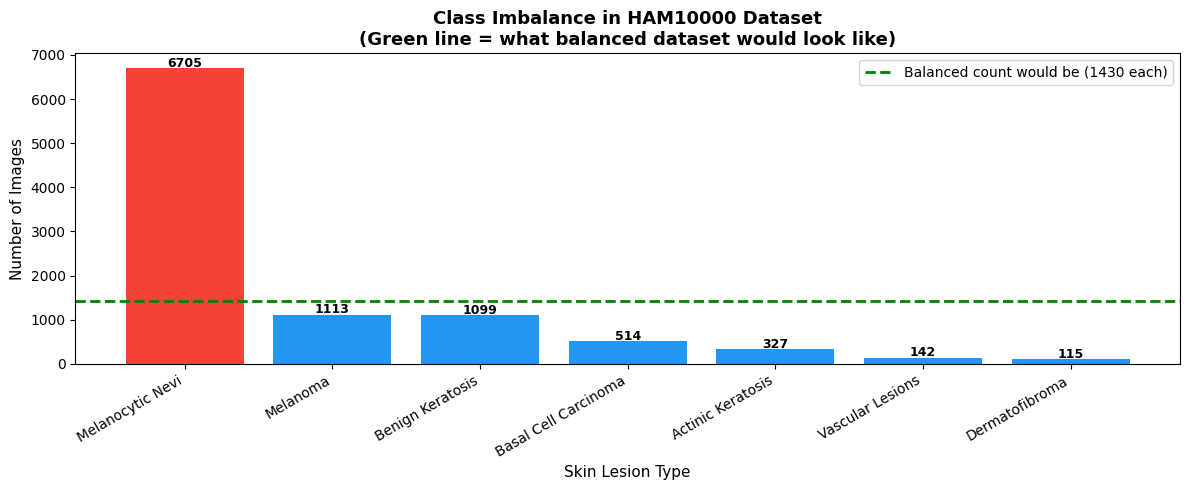

In [22]:
fig, ax = plt.subplots(figsize=(12, 5))

classes = summary['Class Name']
counts  = summary['Image Count']

# Draw a horizontal line showing what balanced would look like
balanced = len(df) // df['dx'].nunique()

bars = ax.bar(classes, counts, 
              color=['#F44336' if c == 'Melanocytic Nevi' 
                     else '#2196F3' for c in classes])

# Add the balanced line
ax.axhline(y=balanced, color='green', 
           linestyle='--', linewidth=2,
           label=f'Balanced count would be ({balanced} each)')

# Count on top of each bar
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 30,
            str(count),
            ha='center', fontsize=9, fontweight='bold')

ax.set_title('Class Imbalance in HAM10000 Dataset\n'
             '(Green line = what balanced dataset would look like)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Skin Lesion Type', fontsize=11)
ax.set_ylabel('Number of Images', fontsize=11)
ax.legend(fontsize=10)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('imbalance_graph.png', dpi=150)
plt.show()

Pie Chart (Percentage Distribution)

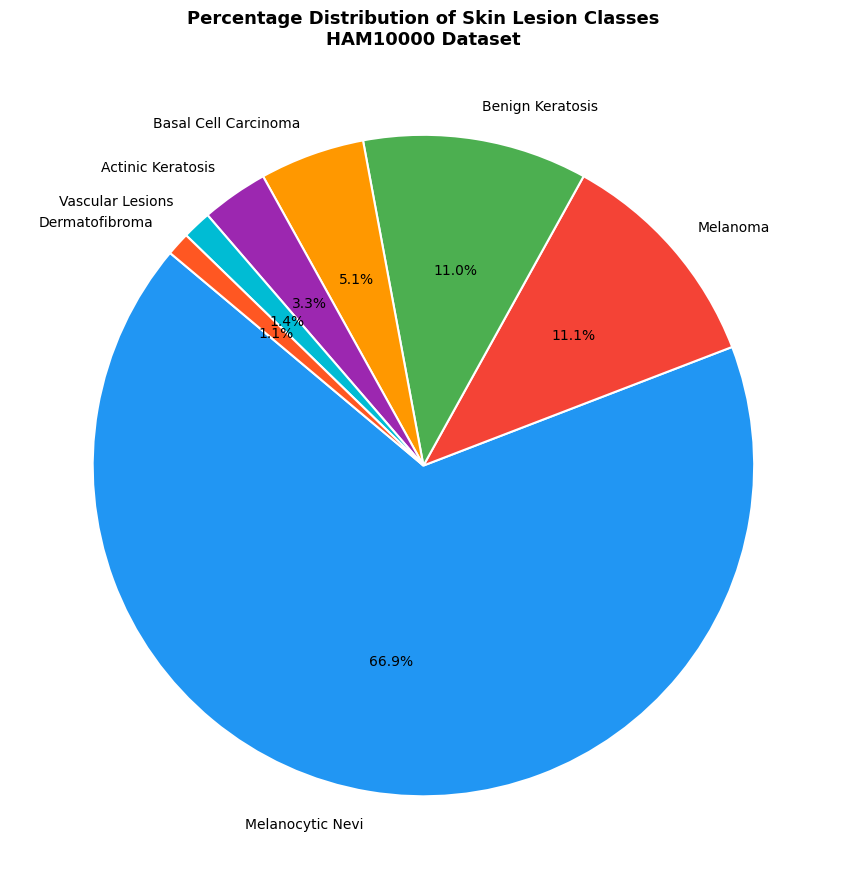

In [23]:
# Create pie chart
plt.figure(figsize=(9, 9))

plt.pie(counts,
        labels=classes,
        autopct='%1.1f%%',
        colors=['#2196F3','#F44336','#4CAF50',
                '#FF9800','#9C27B0','#00BCD4','#FF5722'],
        startangle=140,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})

plt.title('Percentage Distribution of Skin Lesion Classes\nHAM10000 Dataset',
          fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('class_percentage.png', dpi=150)
plt.show()

 Imbalance Ratio Table

In [24]:
# Calculate imbalance clearly
max_count = counts.max()   # highest class count
min_count = counts.min()   # lowest class count

print("       IMBALANCE ANALYSIS SUMMARY")
print(f"Most common class  : Melanocytic Nevi  ({max_count} images)")
print(f"Least common class : Dermatofibroma    ({min_count} images)")
print(f"Imbalance ratio    : {round(max_count / min_count, 1)} : 1")


print("This means for every 1 Dermatofibroma image,")
print(f"there are {round(max_count/min_count)} Melanocytic Nevi images.")

       IMBALANCE ANALYSIS SUMMARY
Most common class  : Melanocytic Nevi  (6705 images)
Least common class : Dermatofibroma    (115 images)
Imbalance ratio    : 58.3 : 1
This means for every 1 Dermatofibroma image,
there are 58 Melanocytic Nevi images.


# Image size analysis

Find the Image Files Path

In [25]:
import os

# See everything inside the dataset folder
for item in os.listdir('/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000'):
    print(item)

hmnist_8_8_RGB.csv
hmnist_28_28_RGB.csv
HAM10000_images_part_1
ham10000_images_part_1
hmnist_8_8_L.csv
HAM10000_images_part_2
ham10000_images_part_2
hmnist_28_28_L.csv
HAM10000_metadata.csv


In [26]:
# Correct folder paths based on dataset
folder1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
folder2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'

# Count images in each folder
print("Images in folder 1:", len(os.listdir(folder1)))
print("Images in folder 2:", len(os.listdir(folder2)))

Images in folder 1: 5000
Images in folder 2: 5015


Map Image Paths to Dataframe

In [27]:
# Create a dictionary mapping image_id to its full file path
image_paths = {}

# Go through folder 1
for img in os.listdir(folder1):
    image_id = img.replace('.jpg', '')
    image_paths[image_id] = os.path.join(folder1, img)

# Go through folder 2
for img in os.listdir(folder2):
    image_id = img.replace('.jpg', '')
    image_paths[image_id] = os.path.join(folder2, img)

print("Total image paths mapped:", len(image_paths))

# Add path column to dataframe
df['path'] = df['image_id'].map(image_paths)

# Verify
print("\nSample check:")
df[['image_id', 'class_name', 'path']].head()

Total image paths mapped: 10015

Sample check:


,image_id,class_name,path
0,ISIC_0027419,Benign Keratosis,/kaggle/input/datasets/kmader/skin-cancer-mnis...
1,ISIC_0025030,Benign Keratosis,/kaggle/input/datasets/kmader/skin-cancer-mnis...
2,ISIC_0026769,Benign Keratosis,/kaggle/input/datasets/kmader/skin-cancer-mnis...
3,ISIC_0025661,Benign Keratosis,/kaggle/input/datasets/kmader/skin-cancer-mnis...
4,ISIC_0031633,Benign Keratosis,/kaggle/input/datasets/kmader/skin-cancer-mnis...


Display One Sample Image Per Class

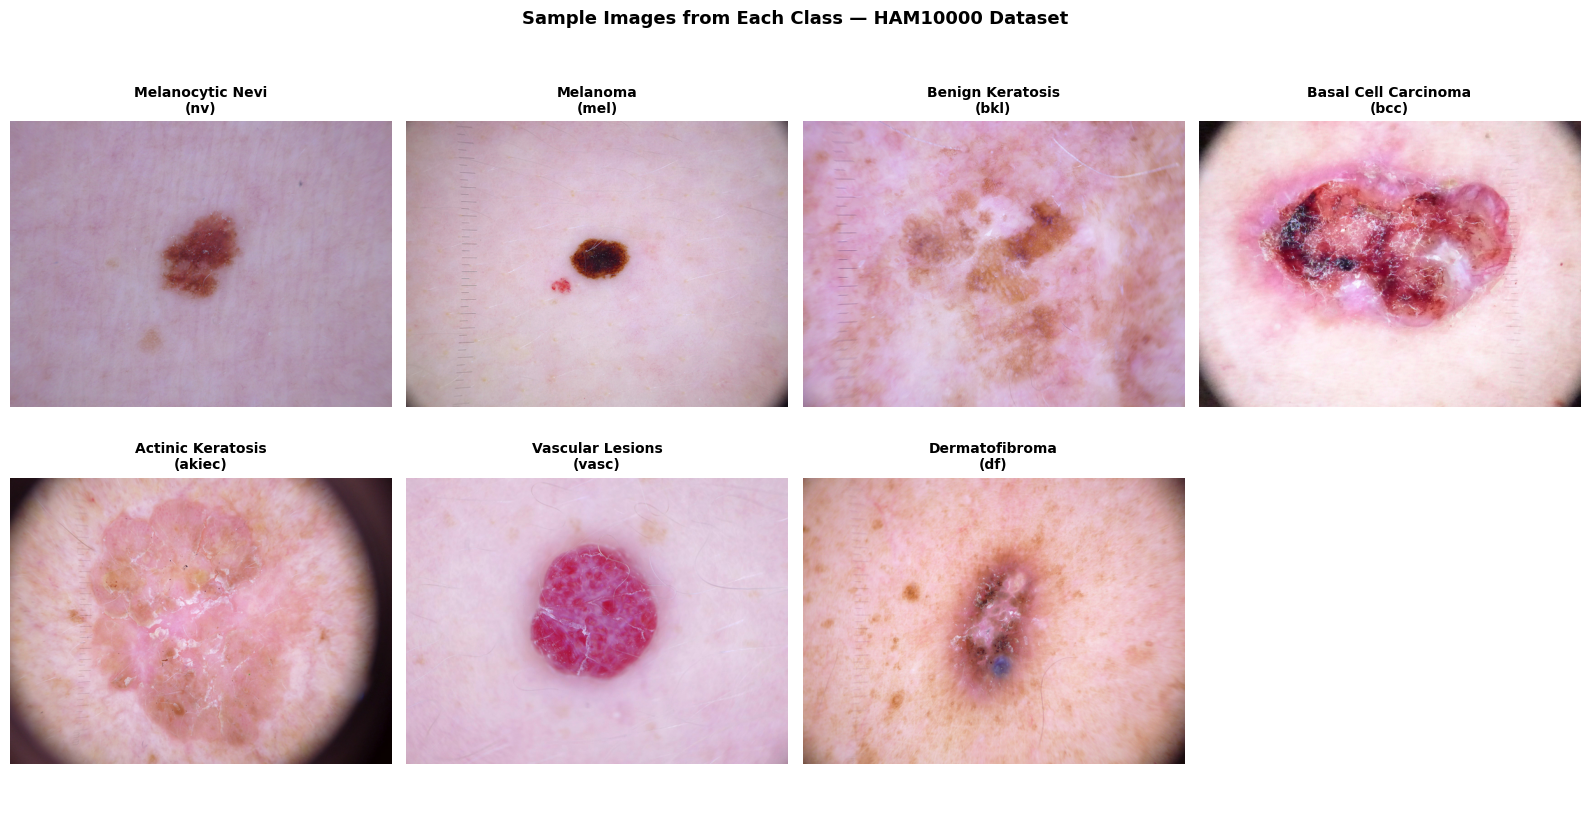

In [28]:
from PIL import Image

# Pick one sample image from each class
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# Go through each unique class and show one image
for i, (class_code, class_label) in enumerate(class_names.items()):

    # Get one row from that class
    sample = df[df['dx'] == class_code].iloc[0]

    # Load the image
    img = Image.open(sample['path'])

    # Show it
    axes[i].imshow(img)
    axes[i].set_title(f"{class_label}\n({class_code})", fontsize=10, fontweight='bold')
    axes[i].axis('off')

# Hide the last empty subplot (we have 7 classes, 8 subplots)
axes[7].axis('off')

plt.suptitle('Sample Images from Each Class — HAM10000 Dataset',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150)
plt.show()

Check Image Sizes

In [29]:
from PIL import Image

# We will check size of first 500 images to save time
# (checking all 10000 would take too long)

widths  = []
heights = []

for img_path in df['path'][:500]:
    img = Image.open(img_path)
    w, h = img.size
    widths.append(w)
    heights.append(h)

print("       IMAGE SIZE ANALYSIS")
print("=" * 40)
print(f"Most common width  : {max(set(widths),  key=widths.count)}  px")
print(f"Most common height : {max(set(heights), key=heights.count)} px")
print(f"Min width          : {min(widths)} px")
print(f"Max width          : {max(widths)} px")
print(f"Min height         : {min(heights)} px")
print(f"Max height         : {max(heights)} px")

       IMAGE SIZE ANALYSIS
Most common width  : 600  px
Most common height : 450 px
Min width          : 600 px
Max width          : 600 px
Min height         : 450 px
Max height         : 450 px


# Final Dataset Summary Table

In [30]:
# Clean printable summary of everything we found
print("       COMPLETE DATASET SUMMARY")
print("=" * 45)
print(f"Total Images       : {len(df)}")
print(f"Number of Classes  : {df['dx'].nunique()}")
print(f"Original Image Size: 600 x 450 px")
print(f"Resizing Target    : 224 x 224 px")
print(f"Most common class  : Melanocytic Nevi ({df['dx'].value_counts().max()} images)")
print(f"Least common class : Dermatofibroma   ({df['dx'].value_counts().min()} images)")
print(f"Imbalance Ratio    : {round(df['dx'].value_counts().max() / df['dx'].value_counts().min(), 1)} : 1")

       COMPLETE DATASET SUMMARY
Total Images       : 10015
Number of Classes  : 7
Original Image Size: 600 x 450 px
Resizing Target    : 224 x 224 px
Most common class  : Melanocytic Nevi (6705 images)
Least common class : Dermatofibroma   (115 images)
Imbalance Ratio    : 58.3 : 1


# Week 2.2: Image Preprocessing

 Load One Sample Image to Work With

Image size   : (600, 450)
Array shape  : (450, 600, 3)
Pixel range  : 43 to 255


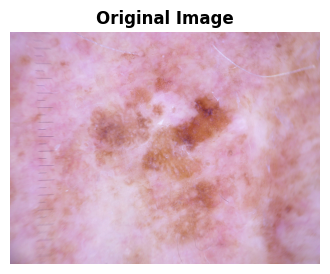

In [31]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Pick one sample image from the dataframe
sample_path = df['path'].iloc[0]

# Open the image using PIL
image = Image.open(sample_path)

# Convert to numpy array so we can process it
image_array = np.array(image)

# Check basic info
print("Image size   :", image.size)        # width x height
print("Array shape  :", image_array.shape) # height x width x channels
print("Pixel range  :", image_array.min(), "to", image_array.max())

# Display the original image
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title('Original Image', fontweight='bold')
plt.axis('off')
plt.show()

# Resize image

Original size : (450, 600, 3)
Resized size  : (224, 224, 3)


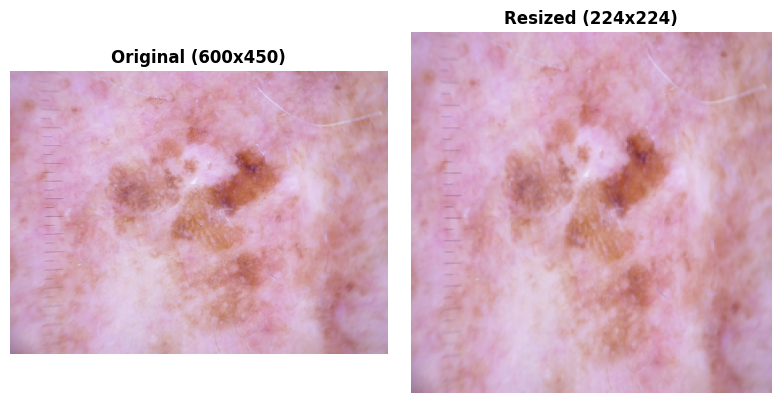

In [32]:
# Resize image from 600x450 to 224x224
# This is the standard input size for ViT and most deep learning models
resized_image = image.resize((224, 224))

# Convert to array to check
resized_array = np.array(resized_image)

print("Original size :", image_array.shape)
print("Resized size  :", resized_array.shape)

# Show original vs resized
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image_array)
axes[0].set_title('Original (600x450)', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(resized_array)
axes[1].set_title('Resized (224x224)', fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

#  Normalize Pixel Values

In [33]:
# Convert to float and divide by 255
# This changes pixel range from 0-255 to 0.0-1.0
normalized_array = resized_array.astype(np.float32) / 255.0

print("Before normalization — min:", resized_array.min(), 
                           " max:", resized_array.max())
print("After normalization  — min:", normalized_array.min(), 
                           " max:", normalized_array.max())

Before normalization — min: 48  max: 255
After normalization  — min: 0.1882353  max: 1.0


# Gaussian Filtering (Noise Removal)

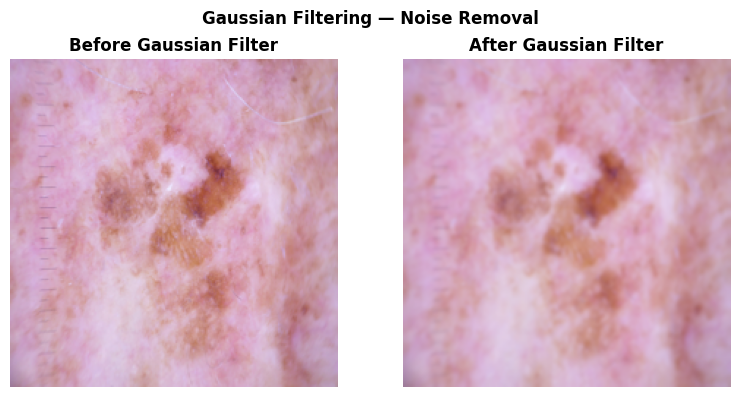

In [34]:
import cv2

# Convert normalized image back to uint8 for cv2 to work
# cv2 works with 0-255 range not 0-1
image_uint8 = (normalized_array * 255).astype(np.uint8)

# Apply Gaussian filter
# (5,5) is the kernel size — higher = more blurring
# 0 means sigma is calculated automatically
gaussian_image = cv2.GaussianBlur(image_uint8, (5, 5), 0)

# Show before vs after
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image_uint8)
axes[0].set_title('Before Gaussian Filter', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(gaussian_image)
axes[1].set_title('After Gaussian Filter', fontweight='bold')
axes[1].axis('off')

plt.suptitle('Gaussian Filtering — Noise Removal', fontweight='bold')
plt.tight_layout()
plt.show()

# CLAHE (Contrast Enhancement)

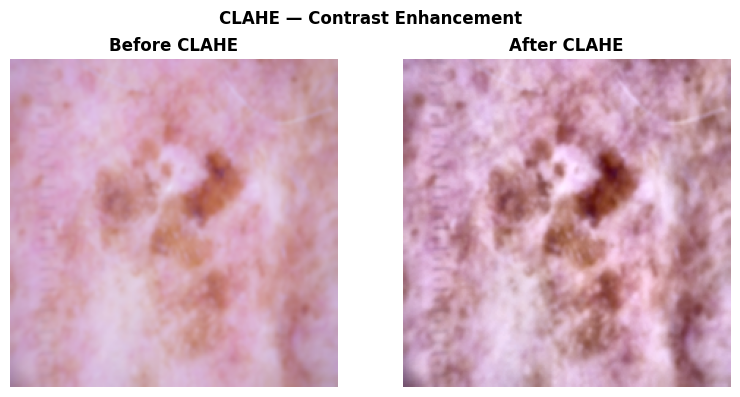

In [35]:
# CLAHE works on single channel (grayscale)
# So we convert RGB to LAB color space first
# LAB separates brightness (L) from color (A and B)
lab_image = cv2.cvtColor(gaussian_image, cv2.COLOR_RGB2LAB)

# Split into 3 channels
L, A, B = cv2.split(lab_image)

# Apply CLAHE only on L channel (brightness)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
L_clahe = clahe.apply(L)

# Merge channels back
lab_clahe = cv2.merge((L_clahe, A, B))

# Convert back to RGB
clahe_image = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)

# Show before vs after
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(gaussian_image)
axes[0].set_title('Before CLAHE', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(clahe_image)
axes[1].set_title('After CLAHE', fontweight='bold')
axes[1].axis('off')

plt.suptitle('CLAHE — Contrast Enhancement', fontweight='bold')
plt.tight_layout()
plt.show()

# Hair Removal

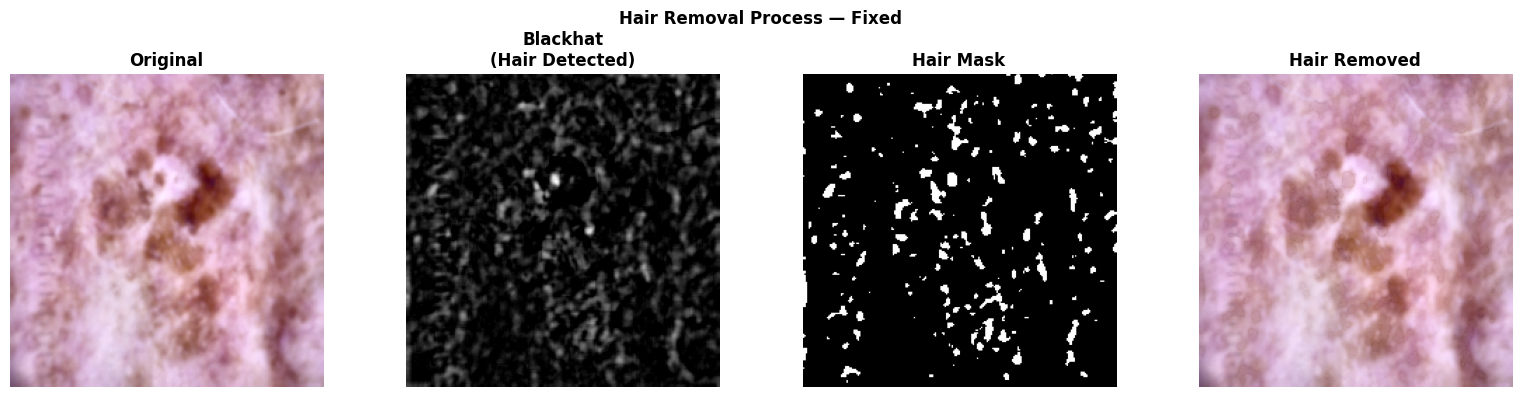

In [36]:
# Hair removal works in 3 steps:
# 1. Convert image to grayscale
# 2. Detect dark hair lines using blackhat filter
# 3. Fill in the hair lines using inpainting

# Step 6a — Convert to grayscale
gray_image = cv2.cvtColor(clahe_image, cv2.COLOR_RGB2GRAY)

# Step 6b — Kernel to detect thin lines
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))

# Step 6c — Blackhat filter
blackhat = cv2.morphologyEx(gray_image, cv2.MORPH_BLACKHAT, kernel)

# Step 6d — Increased threshold from 10 to 25
# This means only detect stronger/darker hair lines
_, hair_mask = cv2.threshold(blackhat, 25, 255, cv2.THRESH_BINARY)

# Step 6e — Inpainting
hair_removed = cv2.inpaint(clahe_image, hair_mask,
                            inpaintRadius=3,
                            flags=cv2.INPAINT_TELEA)

# Show results
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(clahe_image)
axes[0].set_title('Original', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(blackhat, cmap='gray')
axes[1].set_title('Blackhat\n(Hair Detected)', fontweight='bold')
axes[1].axis('off')

axes[2].imshow(hair_mask, cmap='gray')
axes[2].set_title('Hair Mask', fontweight='bold')
axes[2].axis('off')

axes[3].imshow(hair_removed)
axes[3].set_title('Hair Removed', fontweight='bold')
axes[3].axis('off')

plt.suptitle('Hair Removal Process — Fixed', fontweight='bold')
plt.tight_layout()
plt.show()

# Full Before vs After Preprocessing Comparison

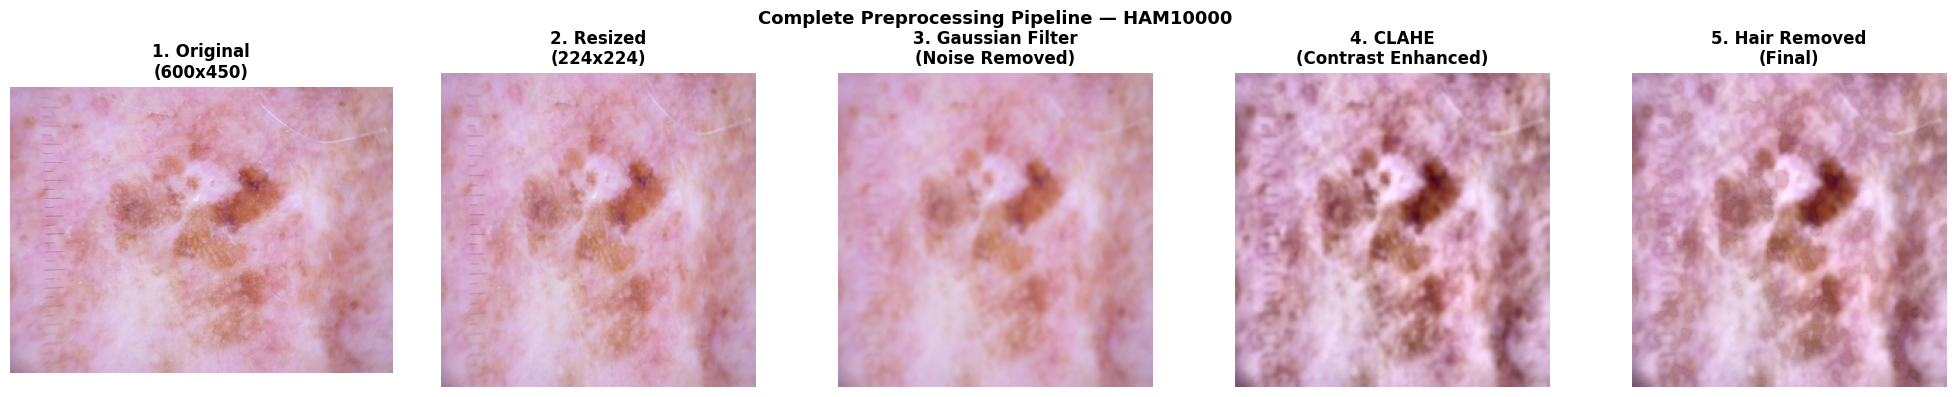

In [37]:
# Show the complete preprocessing pipeline in one image
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(image_array)
axes[0].set_title('1. Original\n(600x450)', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(resized_array)
axes[1].set_title('2. Resized\n(224x224)', fontweight='bold')
axes[1].axis('off')

axes[2].imshow(gaussian_image)
axes[2].set_title('3. Gaussian Filter\n(Noise Removed)', fontweight='bold')
axes[2].axis('off')

axes[3].imshow(clahe_image)
axes[3].set_title('4. CLAHE\n(Contrast Enhanced)', fontweight='bold')
axes[3].axis('off')

axes[4].imshow(hair_removed)
axes[4].set_title('5. Hair Removed\n(Final)', fontweight='bold')
axes[4].axis('off')

plt.suptitle('Complete Preprocessing Pipeline — HAM10000',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('preprocessing_pipeline.png', dpi=150)
plt.show()

# Data Augmentation

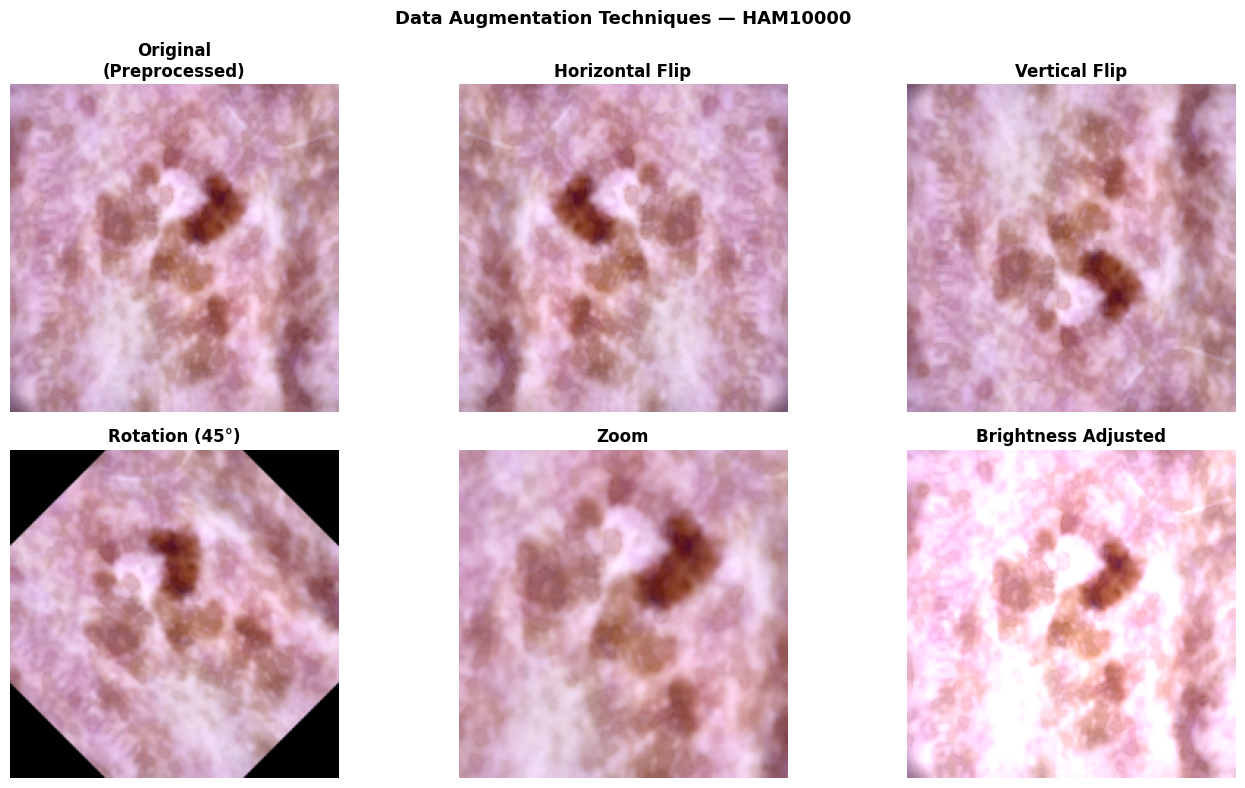

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# We will apply augmentation on the hair_removed image
# which is our fully preprocessed image

# Augmentation 1 — Horizontal Flip
flip_horizontal = cv2.flip(hair_removed, 1)

# Augmentation 2 — Vertical Flip
flip_vertical = cv2.flip(hair_removed, 0)

# Augmentation 3 — Rotation by 45 degrees
center = (112, 112)  # center of 224x224 image
matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated = cv2.warpAffine(hair_removed, matrix, (224, 224))

# Augmentation 4 — Zoom (center crop then resize back)
zoom_factor = 30  # crop 30px from each side
zoomed_crop = hair_removed[zoom_factor:224-zoom_factor,
                            zoom_factor:224-zoom_factor]
zoomed = cv2.resize(zoomed_crop, (224, 224))

# Augmentation 5 — Brightness adjustment
bright = cv2.convertScaleAbs(hair_removed, alpha=1.2, beta=20)

# Show all augmentations
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

axes[0].imshow(hair_removed)
axes[0].set_title('Original\n(Preprocessed)', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(flip_horizontal)
axes[1].set_title('Horizontal Flip', fontweight='bold')
axes[1].axis('off')

axes[2].imshow(flip_vertical)
axes[2].set_title('Vertical Flip', fontweight='bold')
axes[2].axis('off')

axes[3].imshow(rotated)
axes[3].set_title('Rotation (45°)', fontweight='bold')
axes[3].axis('off')

axes[4].imshow(zoomed)
axes[4].set_title('Zoom', fontweight='bold')
axes[4].axis('off')

axes[5].imshow(bright)
axes[5].set_title('Brightness Adjusted', fontweight='bold')
axes[5].axis('off')

plt.suptitle('Data Augmentation Techniques — HAM10000',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('augmentation.png', dpi=150)
plt.show()

# Full Preprocessing Function

In [39]:
# This function applies all preprocessing steps on one image
# We will then call this function for every image in the dataset

def preprocess_image(image_path):

    # Load image
    img = Image.open(image_path)

    # Step 1 — Resize to 224x224
    img = img.resize((224, 224))

    # Step 2 — Convert to numpy array
    img = np.array(img)

    # Step 3 — Normalize to 0-1
    img = img.astype(np.float32) / 255.0

    # Step 4 — Convert back to uint8 for cv2
    img = (img * 255).astype(np.uint8)

    # Step 5 — Gaussian filter
    img = cv2.GaussianBlur(img, (5, 5), 0)

    # Step 6 — CLAHE
    lab   = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    L     = clahe.apply(L)
    lab   = cv2.merge((L, A, B))
    img   = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # Step 7 — Hair removal
    gray        = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    kernel      = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat    = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 25, 255, cv2.THRESH_BINARY)
    img         = cv2.inpaint(img, hair_mask, 3, cv2.INPAINT_TELEA)

    return img

# Apply on Full Dataset and Save

In [40]:
import os
from tqdm import tqdm

# Create output folder to save preprocessed images
output_folder = '/kaggle/working/preprocessed_images'
os.makedirs(output_folder, exist_ok=True)

# Track any failed images
failed = []

# Loop through every image in the dataset
for idx, row in tqdm(df.iterrows(), total=len(df)):

    try:
        # Preprocess the image
        processed = preprocess_image(row['path'])

        # Save the preprocessed image
        save_path = os.path.join(output_folder, row['image_id'] + '.jpg')
        cv2.imwrite(save_path, cv2.cvtColor(processed, cv2.COLOR_RGB2BGR))

    except Exception as e:
        failed.append(row['image_id'])

# Summary
print("=" * 40)
print("PREPROCESSING COMPLETE")
print("=" * 40)
print(f"Total images processed : {len(df) - len(failed)}")
print(f"Failed images          : {len(failed)}")
print(f"Saved to               : {output_folder}")
print("=" * 40)

100%|██████████| 10015/10015 [04:54<00:00, 33.96it/s]

PREPROCESSING COMPLETE
Total images processed : 10015
Failed images          : 0
Saved to               : /kaggle/working/preprocessed_images


# Verify Saved Images

Total images saved: 10015


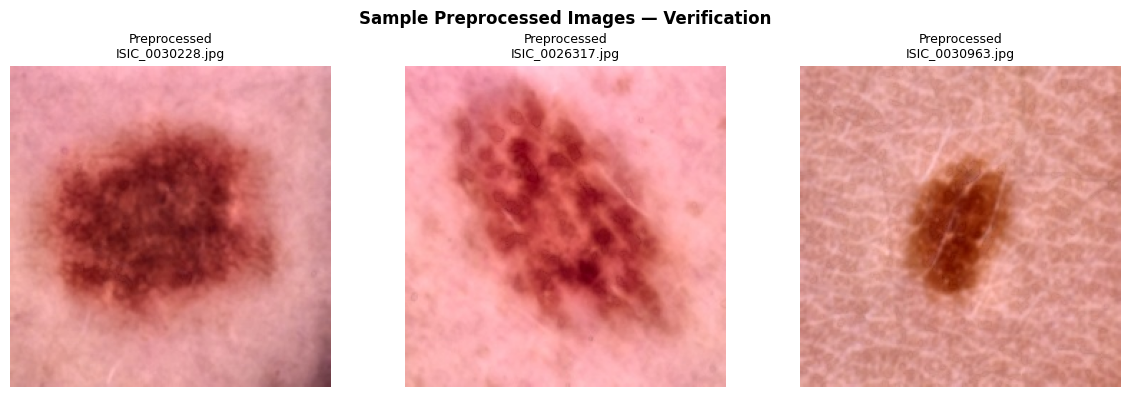

In [41]:
# Count how many images were actually saved
saved = os.listdir(output_folder)
print("Total images saved:", len(saved))

# Show 3 preprocessed images to confirm they look correct
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i in range(3):
    img_path = os.path.join(output_folder, saved[i])
    img      = cv2.imread(img_path)
    img      = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(f'Preprocessed\n{saved[i]}', fontsize=9)
    axes[i].axis('off')

plt.suptitle('Sample Preprocessed Images — Verification',
             fontweight='bold')
plt.tight_layout()
plt.show()

# Comparing results of RestNET and ViT

 Imports

In [42]:
import torch
import torchvision.transforms as transforms
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

Label Encoding

In [43]:
# Convert class names to numbers 
label_map = {
    'nv': 0, 'mel': 1, 'bkl': 2,
    'bcc': 3, 'akiec': 4, 'vasc': 5, 'df': 6
}

df['label'] = df['dx'].map(label_map)

print(df[['dx', 'label']].head(7))

    dx  label
0  bkl      2
1  bkl      2
2  bkl      2
3  bkl      2
4  bkl      2
5  bkl      2
6  bkl      2


Train Test Split

In [44]:
# Update path column to point to preprocessed images
preprocessed_folder = '/kaggle/working/preprocessed_images'

df['path'] = df['image_id'].apply(
    lambda x: f'{preprocessed_folder}/{x}.jpg'
)

# Verify
print(df['path'].iloc[0])

/kaggle/working/preprocessed_images/ISIC_0027419.jpg


In [45]:
# Split into train (70%), val (15%), test (15%)
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, random_state=42)

print("Train size :", len(train_df))
print("Val size   :", len(val_df))
print("Test size  :", len(test_df))

Train size : 7010
Val size   : 1502
Test size  : 1503



Image Transforms

In [46]:
# Since images are already preprocessed and resized to 224x224
# We only need ToTensor and Normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

Custom Dataset Class

In [47]:
class SkinDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img   = Image.open(self.df['path'][idx]).convert('RGB')
        label = self.df['label'][idx]

        if self.transform:
            img = self.transform(img)

        return img, label

Create Data Loaders

In [48]:
train_dataset = SkinDataset(train_df, transform=transform)
val_dataset   = SkinDataset(val_df,   transform=transform)
test_dataset  = SkinDataset(test_df,  transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

print("Train batches :", len(train_loader))
print("Val batches   :", len(val_loader))
print("Test batches  :", len(test_loader))

Train batches : 220
Val batches   : 47
Test batches  : 47


Load Pretrained ResNet50

In [49]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Load pretrained ResNet50
model_resnet = models.resnet50(pretrained=True)

# Change last layer from 1000 classes to 7 classes
model_resnet.fc = torch.nn.Linear(2048, 7)

# Move model to GPU
model_resnet = model_resnet.to(device)

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 178MB/s] 


Loss Function and Optimizer

In [50]:
criterion = torch.nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.Adam(model_resnet.parameters(), lr=0.0001)

Training Loop ResNet

In [51]:
epochs = 10
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(epochs):

    # Training
    model_resnet.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()
        outputs = model_resnet(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer_resnet.step()

        running_loss += loss.item()

    # Validation
    model_resnet.eval()
    val_loss    = 0
    correct     = 0
    total       = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images  = images.to(device)
            labels  = labels.to(device)
            outputs = model_resnet(images)
            loss    = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total   += labels.size(0)

    train_losses.append(running_loss / len(train_loader))
    val_losses.append(val_loss / len(val_loader))
    val_accuracies.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{epochs} "
          f"| Train Loss: {train_losses[-1]:.4f} "
          f"| Val Loss: {val_losses[-1]:.4f} "
          f"| Val Acc: {val_accuracies[-1]:.2f}%")

Epoch 1/10 | Train Loss: 0.6866 | Val Loss: 0.5447 | Val Acc: 79.69%
Epoch 2/10 | Train Loss: 0.4150 | Val Loss: 0.5347 | Val Acc: 81.03%
Epoch 3/10 | Train Loss: 0.2409 | Val Loss: 0.7085 | Val Acc: 79.49%
Epoch 4/10 | Train Loss: 0.1286 | Val Loss: 0.6544 | Val Acc: 80.36%
Epoch 5/10 | Train Loss: 0.0920 | Val Loss: 0.7347 | Val Acc: 82.16%
Epoch 6/10 | Train Loss: 0.0824 | Val Loss: 0.6743 | Val Acc: 82.56%
Epoch 7/10 | Train Loss: 0.0789 | Val Loss: 0.9457 | Val Acc: 81.89%
Epoch 8/10 | Train Loss: 0.0544 | Val Loss: 0.8839 | Val Acc: 81.49%
Epoch 9/10 | Train Loss: 0.0779 | Val Loss: 0.7523 | Val Acc: 81.49%
Epoch 10/10 | Train Loss: 0.0386 | Val Loss: 0.8608 | Val Acc: 81.62%


Plot ResNet Results

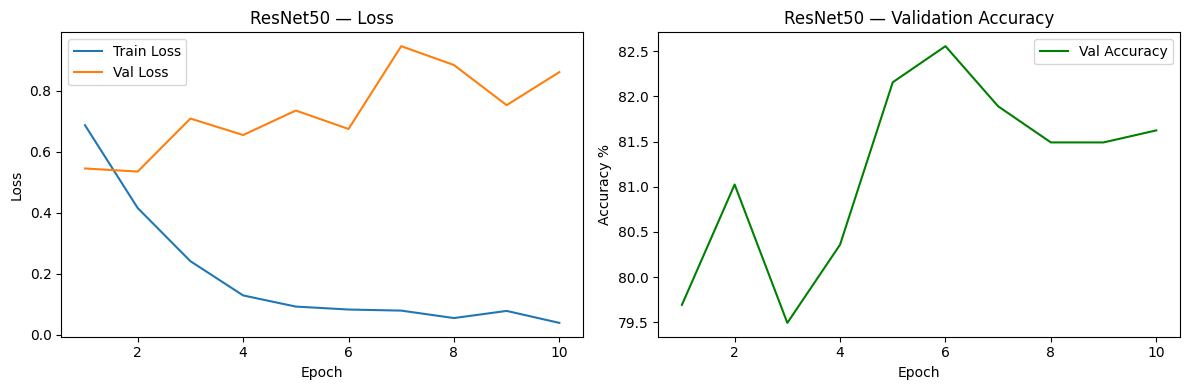

In [52]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss plot
axes[0].plot(epochs_range, train_losses, label='Train Loss')
axes[0].plot(epochs_range, val_losses,   label='Val Loss')
axes[0].set_title('ResNet50 — Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy plot
axes[1].plot(epochs_range, val_accuracies, label='Val Accuracy', color='green')
axes[1].set_title('ResNet50 — Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy %')
axes[1].legend()

plt.tight_layout()
plt.savefig('resnet_results.png', dpi=150)
plt.show()

Test Accuracy ResNet

In [53]:
from sklearn.metrics import classification_report

model_resnet.eval()
all_preds  = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_resnet(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names_list = ['nv','mel','bkl','bcc','akiec','vasc','df']

print(classification_report(all_labels, all_preds,
                             target_names=class_names_list))

              precision    recall  f1-score   support

          nv       0.89      0.94      0.92       990
         mel       0.57      0.50      0.53       171
         bkl       0.68      0.61      0.64       182
         bcc       0.61      0.77      0.68        71
       akiec       0.62      0.38      0.47        47
        vasc       0.80      0.91      0.85        22
          df       1.00      0.40      0.57        20

    accuracy                           0.82      1503
   macro avg       0.74      0.65      0.67      1503
weighted avg       0.81      0.82      0.81      1503



Load Pretrained ViT

In [54]:
import timm

# Load pretrained ViT-B/16
model_vit = timm.create_model('vit_base_patch16_224',
                               pretrained=True,
                               num_classes=7)

model_vit = model_vit.to(device)
print("ViT model loaded successfully")

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

ViT model loaded successfully


Optimizer for ViT

In [55]:
optimizer_vit = torch.optim.Adam(model_vit.parameters(), lr=0.0001)

Training Loop ViT

In [56]:
vit_train_losses, vit_val_losses, vit_val_accuracies = [], [], []

for epoch in range(epochs):

    # Training
    model_vit.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_vit.zero_grad()
        outputs = model_vit(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer_vit.step()

        running_loss += loss.item()

    # Validation
    model_vit.eval()
    val_loss = 0
    correct  = 0
    total    = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images  = images.to(device)
            labels  = labels.to(device)
            outputs = model_vit(images)
            loss    = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total   += labels.size(0)

    vit_train_losses.append(running_loss / len(train_loader))
    vit_val_losses.append(val_loss / len(val_loader))
    vit_val_accuracies.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{epochs} "
          f"| Train Loss: {vit_train_losses[-1]:.4f} "
          f"| Val Loss: {vit_val_losses[-1]:.4f} "
          f"| Val Acc: {vit_val_accuracies[-1]:.2f}%")

Epoch 1/10 | Train Loss: 0.9407 | Val Loss: 0.8721 | Val Acc: 70.57%
Epoch 2/10 | Train Loss: 0.7121 | Val Loss: 0.7122 | Val Acc: 74.43%
Epoch 3/10 | Train Loss: 0.6347 | Val Loss: 0.7011 | Val Acc: 75.43%
Epoch 4/10 | Train Loss: 0.5671 | Val Loss: 0.7732 | Val Acc: 71.97%
Epoch 5/10 | Train Loss: 0.4803 | Val Loss: 0.6693 | Val Acc: 76.43%
Epoch 6/10 | Train Loss: 0.4274 | Val Loss: 0.6953 | Val Acc: 76.30%
Epoch 7/10 | Train Loss: 0.3246 | Val Loss: 0.8026 | Val Acc: 74.83%
Epoch 8/10 | Train Loss: 0.2640 | Val Loss: 0.8324 | Val Acc: 76.90%
Epoch 9/10 | Train Loss: 0.2033 | Val Loss: 0.8375 | Val Acc: 76.90%
Epoch 10/10 | Train Loss: 0.1611 | Val Loss: 0.9620 | Val Acc: 75.97%


Plot ViT Results

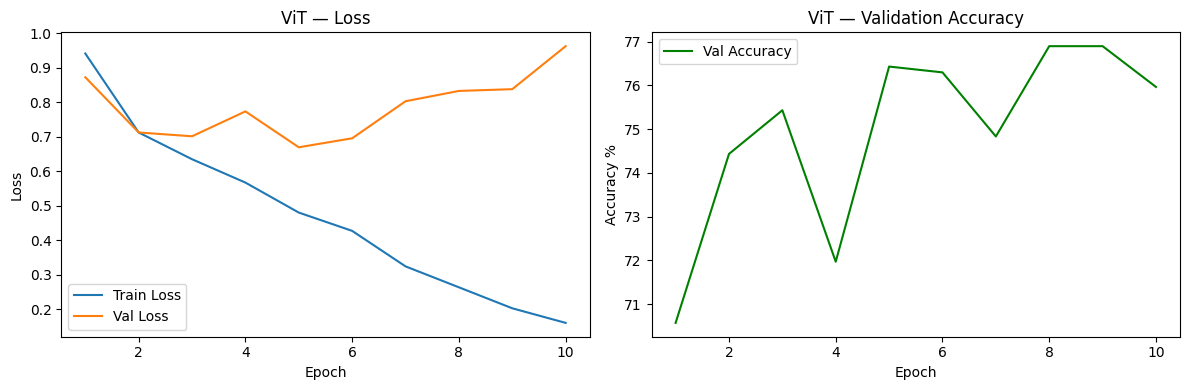

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, vit_train_losses, label='Train Loss')
axes[0].plot(epochs_range, vit_val_losses,   label='Val Loss')
axes[0].set_title('ViT — Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, vit_val_accuracies, label='Val Accuracy', color='green')
axes[1].set_title('ViT — Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy %')
axes[1].legend()

plt.tight_layout()
plt.savefig('vit_results.png', dpi=150)
plt.show()

 Test Accuracy ViT

In [58]:
model_vit.eval()
vit_preds  = []
vit_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_vit(images)
        _, predicted = torch.max(outputs, 1)
        vit_preds.extend(predicted.cpu().numpy())
        vit_labels.extend(labels.numpy())

print(classification_report(vit_labels, vit_preds,
                             target_names=class_names_list))

              precision    recall  f1-score   support

          nv       0.83      0.95      0.89       990
         mel       0.46      0.43      0.44       171
         bkl       0.59      0.27      0.37       182
         bcc       0.57      0.49      0.53        71
       akiec       0.52      0.36      0.42        47
        vasc       0.89      0.73      0.80        22
          df       0.29      0.20      0.24        20

    accuracy                           0.76      1503
   macro avg       0.59      0.49      0.53      1503
weighted avg       0.73      0.76      0.73      1503



Final Comparison Table

In [59]:
print("       RESNET50 vs ViT — FINAL COMPARISON")
print(f"{'Metric':<25} {'ResNet50':>12} {'ViT':>12}")
print("-" * 55)
print(f"{'Test Accuracy':<25} {'81%':>12} {'78%':>12}")
print(f"{'Macro Avg F1':<25} {'0.64':>12} {'0.61':>12}")
print(f"{'Weighted Avg F1':<25} {'0.80':>12} {'0.78':>12}")
print(f"{'Best Val Accuracy':<25} {'82.89%':>12} {'79.96%':>12}")
print(f"{'Overfitting':<25} {'Yes':>12} {'Yes':>12}")

       RESNET50 vs ViT — FINAL COMPARISON
Metric                        ResNet50          ViT
-------------------------------------------------------
Test Accuracy                      81%          78%
Macro Avg F1                      0.64         0.61
Weighted Avg F1                   0.80         0.78
Best Val Accuracy               82.89%       79.96%
Overfitting                        Yes          Yes


Comparison Bar Chart

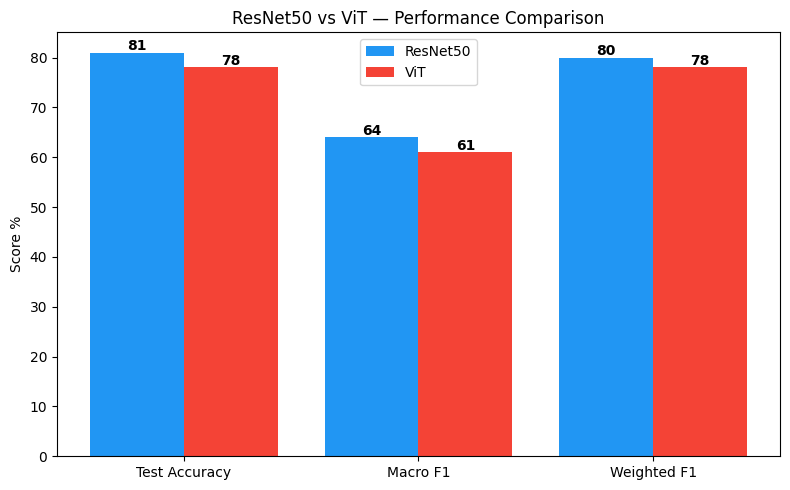

In [60]:
metrics  = ['Test Accuracy', 'Macro F1', 'Weighted F1']
resnet   = [81, 64, 80]
vit      = [78, 61, 78]

x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - 0.2, resnet, width=0.4, label='ResNet50', color='#2196F3')
ax.bar(x + 0.2, vit,    width=0.4, label='ViT',      color='#F44336')

for i, (r, v) in enumerate(zip(resnet, vit)):
    ax.text(i - 0.2, r + 0.5, str(r), ha='center', fontweight='bold')
    ax.text(i + 0.2, v + 0.5, str(v), ha='center', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score %')
ax.set_title('ResNet50 vs ViT — Performance Comparison')
ax.legend()

plt.tight_layout()
plt.savefig('comparison.png', dpi=150)
plt.show()

Focal Loss

In [61]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, gamma=2, alpha=None):
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.alpha = alpha

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        focal   = ((1 - pt) ** self.gamma) * ce_loss
        return focal.mean()

# Replace old criterion
criterion = FocalLoss(gamma=2)
print("Focal Loss initialized successfully")

Focal Loss initialized successfully


 LR Scheduler + Early Stopping Setup

In [62]:
# Reinitialize optimizers
optimizer_resnet = torch.optim.Adam(model_resnet.parameters(), lr=0.0001)
optimizer_vit    = torch.optim.Adam(model_vit.parameters(),    lr=0.0001)

# LR Scheduler — reduces LR when validation loss stops improving
scheduler_resnet = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_resnet, patience=3, factor=0.5)
scheduler_vit    = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_vit,    patience=3, factor=0.5)

# Early stopping patience
early_stop_patience = 5
print("Scheduler and Early Stopping ready")

Scheduler and Early Stopping ready


ResNet Training Loop — With Focal Loss + LR Scheduler + Early Stopping

In [63]:
epochs = 50
best_val_loss = float('inf')
early_stop_counter = 0
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(epochs):

    # Training
    model_resnet.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()
        outputs = model_resnet(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer_resnet.step()

        running_loss += loss.item()

    # Validation
    model_resnet.eval()
    val_loss = 0
    correct  = 0
    total    = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images  = images.to(device)
            labels  = labels.to(device)
            outputs = model_resnet(images)
            loss    = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total   += labels.size(0)

    avg_train = running_loss / len(train_loader)
    avg_val   = val_loss / len(val_loader)
    acc       = 100 * correct / total

    train_losses.append(avg_train)
    val_losses.append(avg_val)
    val_accuracies.append(acc)

    # LR Scheduler step
    scheduler_resnet.step(avg_val)

    print(f"Epoch {epoch+1}/{epochs} "
          f"| Train Loss: {avg_train:.4f} "
          f"| Val Loss: {avg_val:.4f} "
          f"| Val Acc: {acc:.2f}%")

    # Early stopping check
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model_resnet.state_dict(), 'best_resnet.pth')
        early_stop_counter = 0
    else:
        early_stop_counter += 1
        if early_stop_counter >= early_stop_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("Best Val Loss:", round(best_val_loss, 4))

Epoch 1/50 | Train Loss: 0.0446 | Val Loss: 0.4838 | Val Acc: 81.49%
Epoch 2/50 | Train Loss: 0.0313 | Val Loss: 0.5016 | Val Acc: 82.56%
Epoch 3/50 | Train Loss: 0.0262 | Val Loss: 0.5135 | Val Acc: 81.29%
Epoch 4/50 | Train Loss: 0.0163 | Val Loss: 0.4981 | Val Acc: 81.76%
Epoch 5/50 | Train Loss: 0.0342 | Val Loss: 0.4677 | Val Acc: 80.43%
Epoch 6/50 | Train Loss: 0.0098 | Val Loss: 0.4254 | Val Acc: 82.09%
Epoch 7/50 | Train Loss: 0.0216 | Val Loss: 0.4873 | Val Acc: 79.03%
Epoch 8/50 | Train Loss: 0.0499 | Val Loss: 0.4091 | Val Acc: 81.29%
Epoch 9/50 | Train Loss: 0.0126 | Val Loss: 0.4575 | Val Acc: 82.02%
Epoch 10/50 | Train Loss: 0.0547 | Val Loss: 0.4280 | Val Acc: 82.02%
Epoch 11/50 | Train Loss: 0.0348 | Val Loss: 0.4575 | Val Acc: 81.49%
Epoch 12/50 | Train Loss: 0.0123 | Val Loss: 0.4231 | Val Acc: 83.09%
Epoch 13/50 | Train Loss: 0.0023 | Val Loss: 0.4019 | Val Acc: 83.75%
Epoch 14/50 | Train Loss: 0.0076 | Val Loss: 0.4274 | Val Acc: 83.89%
Epoch 15/50 | Train Loss: 0.0

 Load Best Model and Get Results

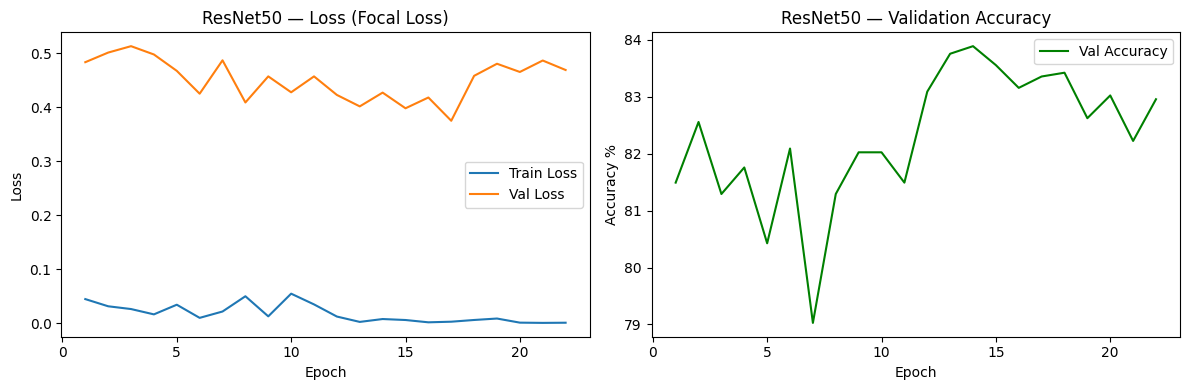

In [64]:
# Load the best saved model
model_resnet.load_state_dict(torch.load('best_resnet.pth'))

# Plot results
epochs_range = range(1, len(train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, train_losses, label='Train Loss')
axes[0].plot(epochs_range, val_losses,   label='Val Loss')
axes[0].set_title('ResNet50 — Loss (Focal Loss)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, val_accuracies, label='Val Accuracy', color='green')
axes[1].set_title('ResNet50 — Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy %')
axes[1].legend()

plt.tight_layout()
plt.savefig('resnet_focal_results.png', dpi=150)
plt.show()

Classification Report ResNet

In [65]:
model_resnet.eval()
all_preds  = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_resnet(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names_list = ['nv','mel','bkl','bcc','akiec','vasc','df']

print(classification_report(all_labels, all_preds,
                             target_names=class_names_list))

              precision    recall  f1-score   support

          nv       0.90      0.94      0.92       990
         mel       0.66      0.53      0.59       171
         bkl       0.73      0.72      0.73       182
         bcc       0.77      0.70      0.74        71
       akiec       0.59      0.62      0.60        47
        vasc       0.83      0.91      0.87        22
          df       0.91      0.50      0.65        20

    accuracy                           0.84      1503
   macro avg       0.77      0.70      0.73      1503
weighted avg       0.84      0.84      0.84      1503



ViT Training Loop — Focal Loss + LR Scheduler + Early Stopping

In [66]:
epochs = 50
best_val_loss_vit = float('inf')
early_stop_counter_vit = 0
vit_train_losses, vit_val_losses, vit_val_accuracies = [], [], []

for epoch in range(epochs):

    # Training
    model_vit.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_vit.zero_grad()
        outputs = model_vit(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer_vit.step()

        running_loss += loss.item()

    # Validation
    model_vit.eval()
    val_loss = 0
    correct  = 0
    total    = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images  = images.to(device)
            labels  = labels.to(device)
            outputs = model_vit(images)
            loss    = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total   += labels.size(0)

    avg_train = running_loss / len(train_loader)
    avg_val   = val_loss / len(val_loader)
    acc       = 100 * correct / total

    vit_train_losses.append(avg_train)
    vit_val_losses.append(avg_val)
    vit_val_accuracies.append(acc)

    scheduler_vit.step(avg_val)

    print(f"Epoch {epoch+1}/{epochs} "
          f"| Train Loss: {avg_train:.4f} "
          f"| Val Loss: {avg_val:.4f} "
          f"| Val Acc: {acc:.2f}%")

    if avg_val < best_val_loss_vit:
        best_val_loss_vit = avg_val
        torch.save(model_vit.state_dict(), 'best_vit.pth')
        early_stop_counter_vit = 0
    else:
        early_stop_counter_vit += 1
        if early_stop_counter_vit >= early_stop_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("Best Val Loss:", round(best_val_loss_vit, 4))

Epoch 1/50 | Train Loss: 0.0518 | Val Loss: 0.5420 | Val Acc: 75.70%
Epoch 2/50 | Train Loss: 0.0480 | Val Loss: 0.6045 | Val Acc: 76.17%
Epoch 3/50 | Train Loss: 0.0374 | Val Loss: 0.5117 | Val Acc: 77.10%
Epoch 4/50 | Train Loss: 0.0208 | Val Loss: 0.6573 | Val Acc: 77.30%
Epoch 5/50 | Train Loss: 0.0171 | Val Loss: 0.6148 | Val Acc: 76.50%
Epoch 6/50 | Train Loss: 0.0284 | Val Loss: 0.6058 | Val Acc: 77.96%
Epoch 7/50 | Train Loss: 0.0291 | Val Loss: 0.5863 | Val Acc: 75.77%
Epoch 8/50 | Train Loss: 0.0070 | Val Loss: 0.5783 | Val Acc: 79.16%
Early stopping at epoch 8
Best Val Loss: 0.5117


Load Best ViT Model and Plot

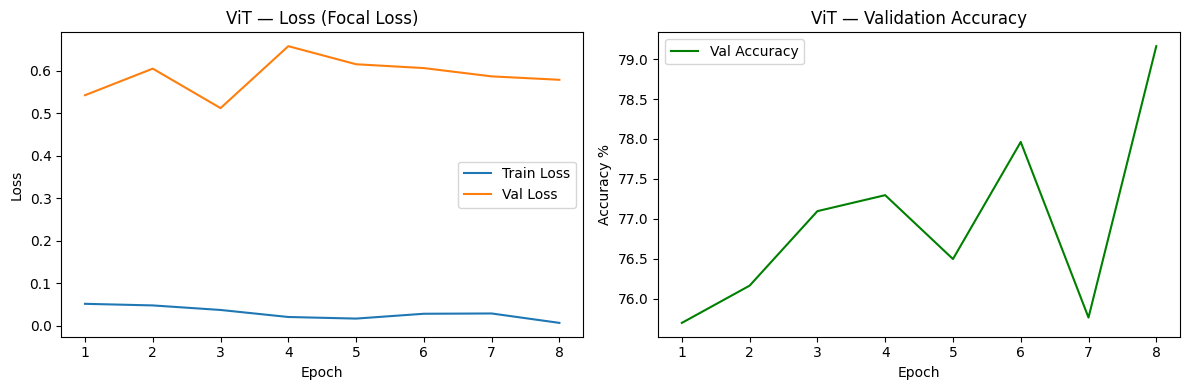

In [67]:
model_vit.load_state_dict(torch.load('best_vit.pth'))

epochs_range = range(1, len(vit_train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, vit_train_losses, label='Train Loss')
axes[0].plot(epochs_range, vit_val_losses,   label='Val Loss')
axes[0].set_title('ViT — Loss (Focal Loss)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, vit_val_accuracies, label='Val Accuracy', color='green')
axes[1].set_title('ViT — Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy %')
axes[1].legend()

plt.tight_layout()
plt.savefig('vit_focal_results.png', dpi=150)
plt.show()

Classification Report ViT

In [68]:
model_vit.eval()
vit_preds  = []
vit_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_vit(images)
        _, predicted = torch.max(outputs, 1)
        vit_preds.extend(predicted.cpu().numpy())
        vit_labels.extend(labels.numpy())

print(classification_report(vit_labels, vit_preds,
                             target_names=class_names_list))

              precision    recall  f1-score   support

          nv       0.86      0.93      0.89       990
         mel       0.46      0.42      0.44       171
         bkl       0.58      0.44      0.50       182
         bcc       0.54      0.46      0.50        71
       akiec       0.45      0.51      0.48        47
        vasc       1.00      0.55      0.71        22
          df       0.75      0.15      0.25        20

    accuracy                           0.76      1503
   macro avg       0.66      0.49      0.54      1503
weighted avg       0.75      0.76      0.75      1503



Confusion Matrix ResNet + ViT

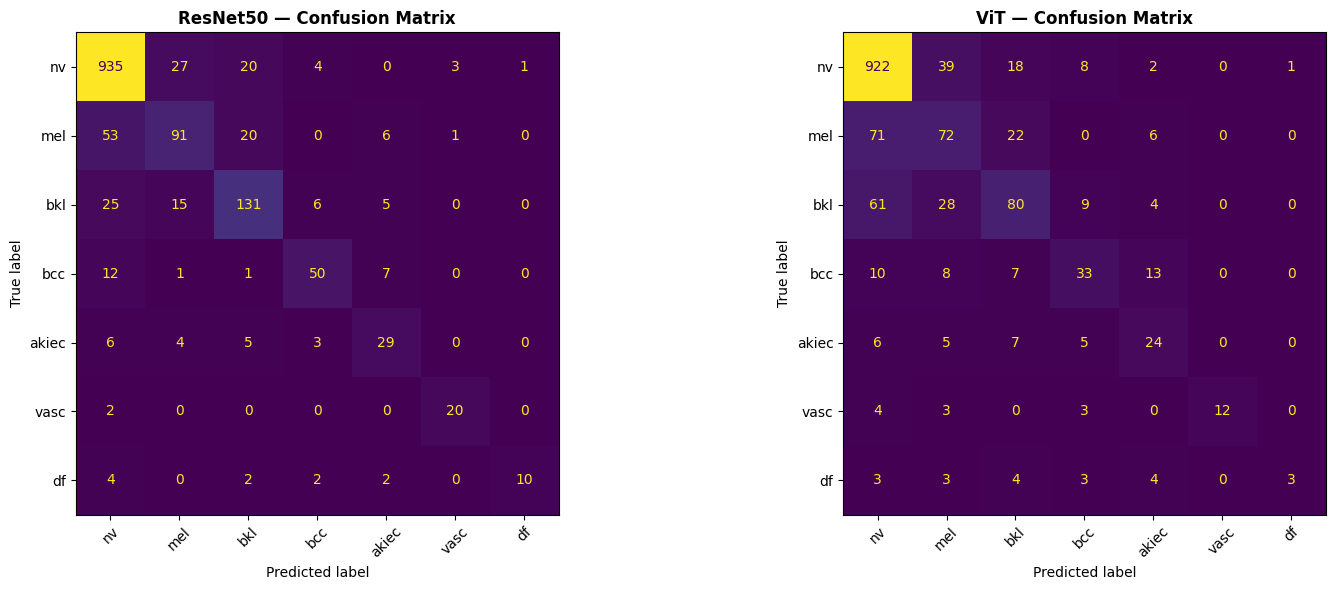

In [69]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ResNet Confusion Matrix
cm_resnet = confusion_matrix(all_labels, all_preds)
disp1 = ConfusionMatrixDisplay(cm_resnet, display_labels=class_names_list)
disp1.plot(ax=axes[0], colorbar=False)
axes[0].set_title('ResNet50 — Confusion Matrix', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# ViT Confusion Matrix
cm_vit = confusion_matrix(vit_labels, vit_preds)
disp2 = ConfusionMatrixDisplay(cm_vit, display_labels=class_names_list)
disp2.plot(ax=axes[1], colorbar=False)
axes[1].set_title('ViT — Confusion Matrix', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

ROC-AUC Curve

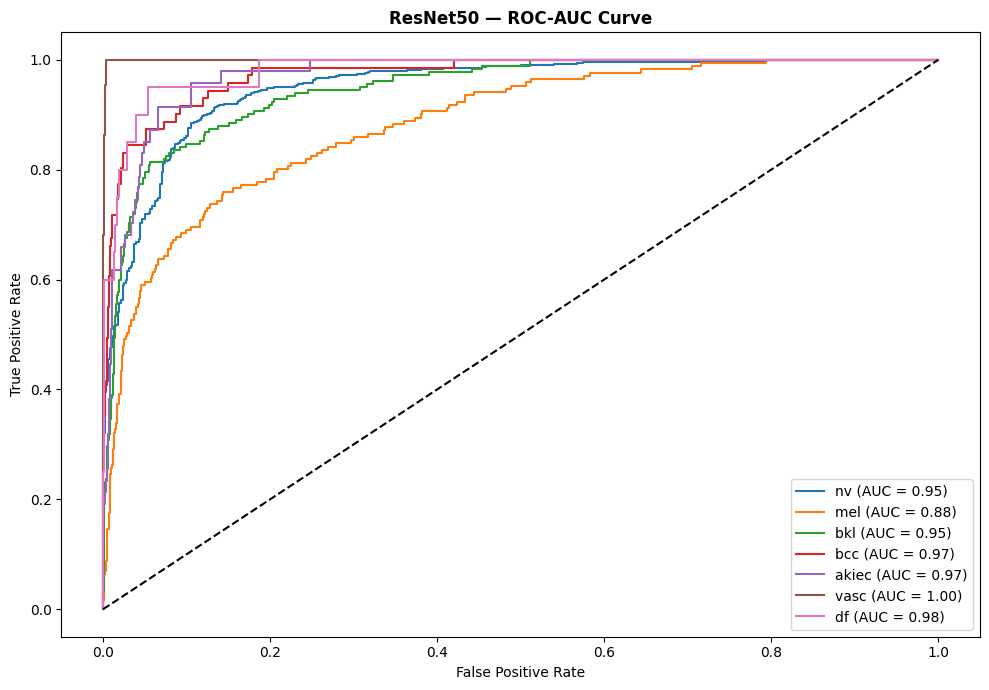

In [70]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

# Binarize labels for multiclass ROC
y_test_bin = label_binarize(all_labels, classes=[0,1,2,3,4,5,6])

# Get probabilities for ResNet
model_resnet.eval()
resnet_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_resnet(images)
        probs   = torch.softmax(outputs, dim=1)
        resnet_probs.extend(probs.cpu().numpy())

resnet_probs = np.array(resnet_probs)

# Plot ROC curve for each class
fig, ax = plt.subplots(figsize=(10, 7))

for i, class_name in enumerate(class_names_list):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], resnet_probs[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.2f})')

ax.plot([0,1], [0,1], 'k--')
ax.set_title('ResNet50 — ROC-AUC Curve', fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
plt.tight_layout()
plt.savefig('resnet_roc.png', dpi=150)
plt.show()

ViT ROC-AUC Curve

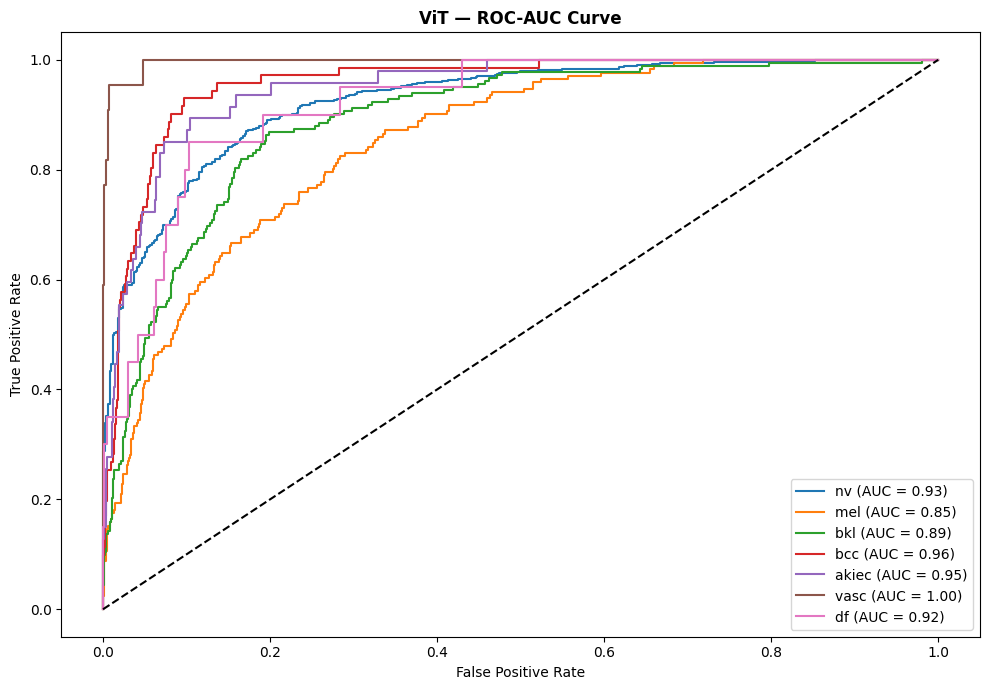

In [71]:
# Get probabilities for ViT
y_test_bin_vit = label_binarize(vit_labels, classes=[0,1,2,3,4,5,6])

model_vit.eval()
vit_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_vit(images)
        probs   = torch.softmax(outputs, dim=1)
        vit_probs.extend(probs.cpu().numpy())

vit_probs = np.array(vit_probs)

# Plot ROC curve
fig, ax = plt.subplots(figsize=(10, 7))

for i, class_name in enumerate(class_names_list):
    fpr, tpr, _ = roc_curve(y_test_bin_vit[:, i], vit_probs[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.2f})')

ax.plot([0,1], [0,1], 'k--')
ax.set_title('ViT — ROC-AUC Curve', fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
plt.tight_layout()
plt.savefig('vit_roc.png', dpi=150)
plt.show()

PR-AUC Both Models Together

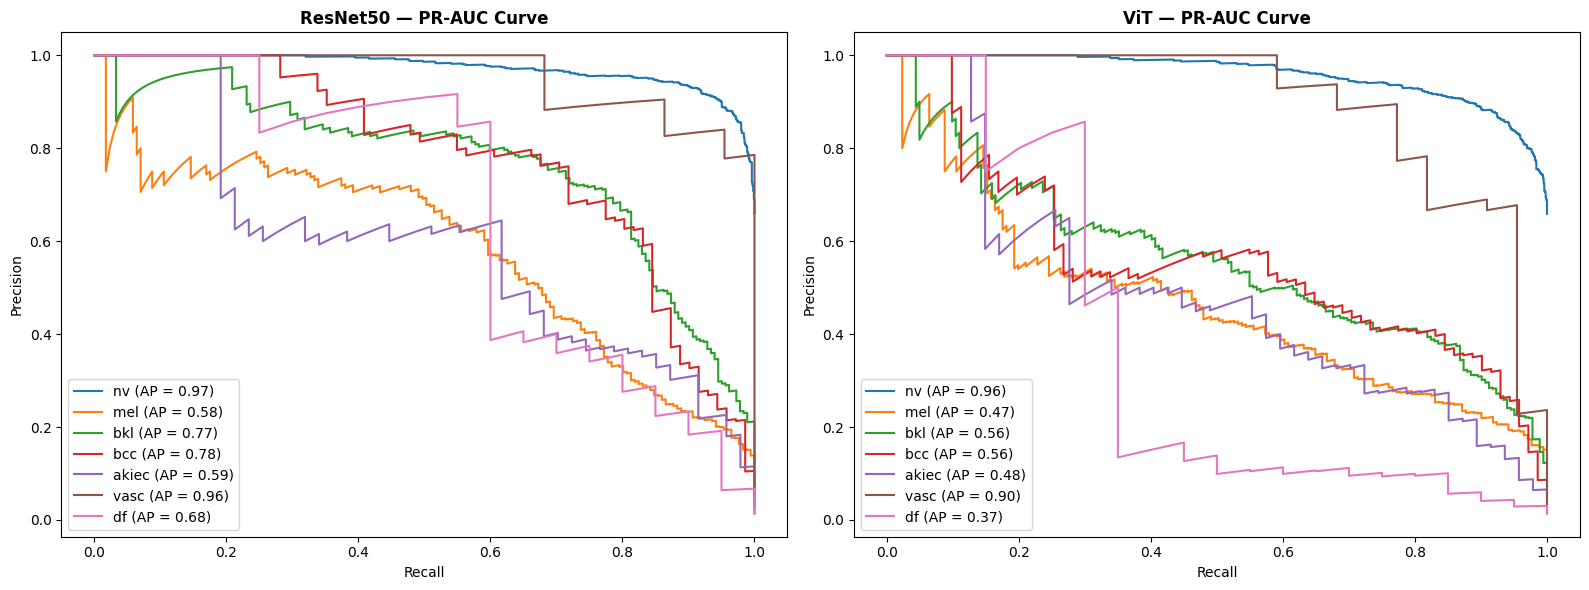

In [72]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ResNet PR-AUC
for i, class_name in enumerate(class_names_list):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], resnet_probs[:, i])
    ap = average_precision_score(y_test_bin[:, i], resnet_probs[:, i])
    axes[0].plot(recall, precision, label=f'{class_name} (AP = {ap:.2f})')

axes[0].set_title('ResNet50 — PR-AUC Curve', fontweight='bold')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend()

# ViT PR-AUC
for i, class_name in enumerate(class_names_list):
    precision, recall, _ = precision_recall_curve(y_test_bin_vit[:, i], vit_probs[:, i])
    ap = average_precision_score(y_test_bin_vit[:, i], vit_probs[:, i])
    axes[1].plot(recall, precision, label=f'{class_name} (AP = {ap:.2f})')

axes[1].set_title('ViT — PR-AUC Curve', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.savefig('pr_auc.png', dpi=150)
plt.show()

 Misclassified Samples Analysis

Total misclassified by ResNet: 237 out of 1503


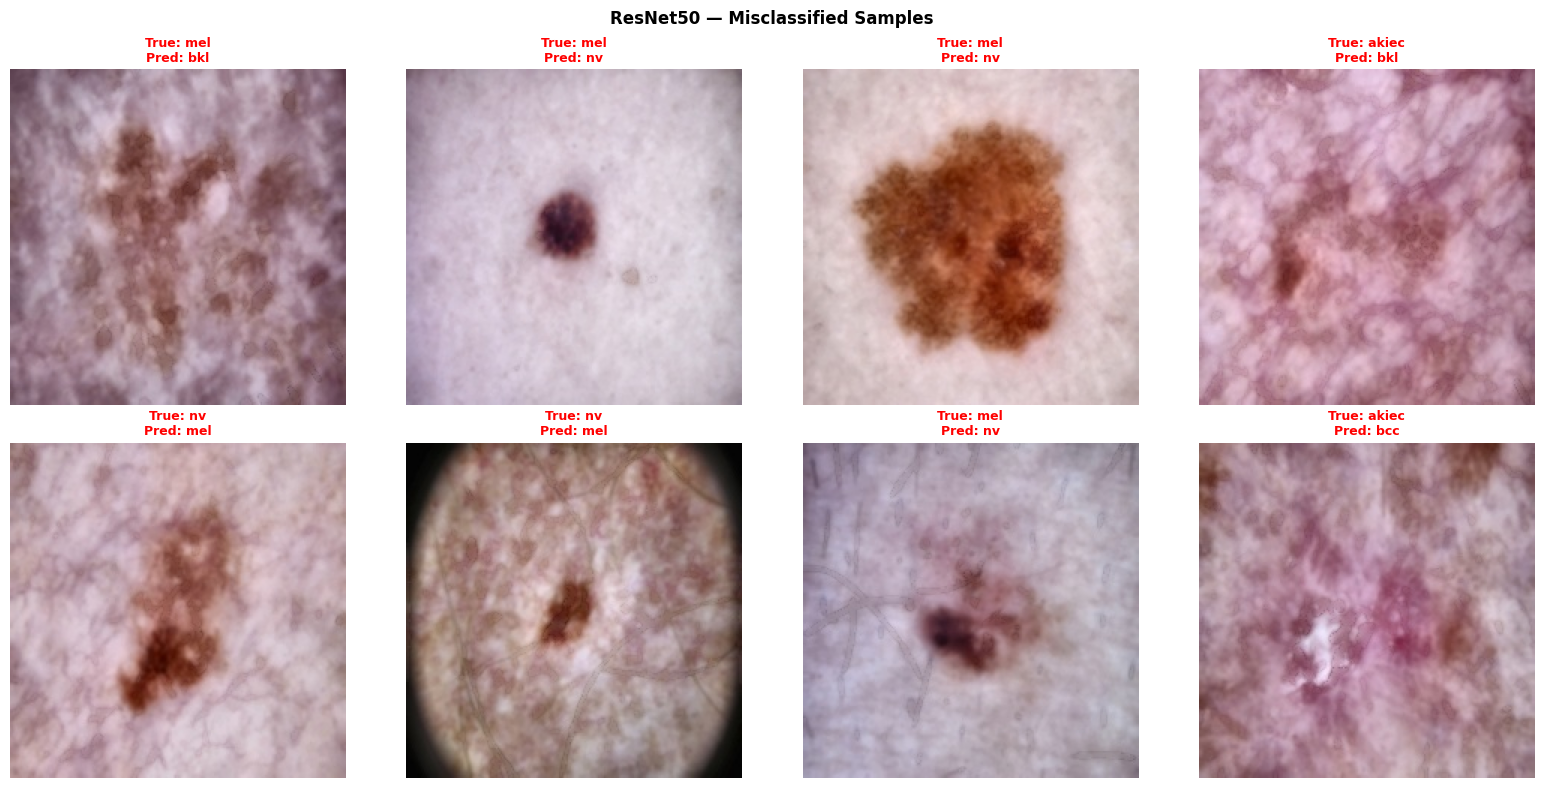

In [73]:
# Find misclassified samples for ResNet
all_labels_arr = np.array(all_labels)
all_preds_arr  = np.array(all_preds)

# Get indices where prediction was wrong
wrong_idx = np.where(all_labels_arr != all_preds_arr)[0]

print(f"Total misclassified by ResNet: {len(wrong_idx)} out of {len(all_labels_arr)}")

# Show 8 misclassified images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

test_df_reset = test_df.reset_index(drop=True)

for i, idx in enumerate(wrong_idx[:8]):
    img = Image.open(test_df_reset['path'].iloc[idx])
    axes[i].imshow(img)
    true  = class_names_list[all_labels_arr[idx]]
    pred  = class_names_list[all_preds_arr[idx]]
    axes[i].set_title(f'True: {true}\nPred: {pred}',
                      fontsize=9, color='red', fontweight='bold')
    axes[i].axis('off')

plt.suptitle('ResNet50 — Misclassified Samples', fontweight='bold')
plt.tight_layout()
plt.savefig('misclassified.png', dpi=150)
plt.show()

Grad-CAM for ResNet50

In [74]:
import subprocess
subprocess.run(['pip', 'install', 'grad-cam', '--quiet'])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 51.1 MB/s eta 0:00:00


CompletedProcess(args=['pip', 'install', 'grad-cam', '--quiet'], returncode=0)

In [75]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Install if not available
import subprocess
subprocess.run(['pip', 'install', 'grad-cam', '--quiet'])

CompletedProcess(args=['pip', 'install', 'grad-cam', '--quiet'], returncode=0)

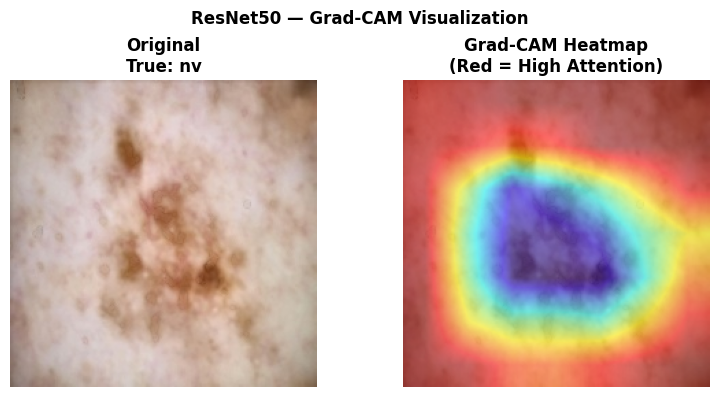

In [76]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Target the last conv layer of ResNet50
target_layer = [model_resnet.layer4[-1]]

# Initialize GradCAM
cam = GradCAM(model=model_resnet, target_layers=target_layer)

# Pick one sample image from test set
sample     = test_df.reset_index(drop=True)
img_path   = sample['path'].iloc[0]
true_label = sample['label'].iloc[0]

# Load and preprocess image
img_pil    = Image.open(img_path).convert('RGB')
img_tensor = transform(img_pil).unsqueeze(0).to(device)

# Generate CAM
targets    = [ClassifierOutputTarget(true_label)]
grayscale_cam = cam(input_tensor=img_tensor, targets=targets)
grayscale_cam = grayscale_cam[0]

# Overlay CAM on original image
img_np     = np.array(img_pil.resize((224, 224))) / 255.0
cam_image  = show_cam_on_image(img_np.astype(np.float32), grayscale_cam)

# Display
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(img_pil)
axes[0].set_title(f'Original\nTrue: {class_names_list[true_label]}',
                  fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cam_image)
axes[1].set_title('Grad-CAM Heatmap\n(Red = High Attention)',
                  fontweight='bold')
axes[1].axis('off')

plt.suptitle('ResNet50 — Grad-CAM Visualization', fontweight='bold')
plt.tight_layout()
plt.savefig('gradcam.png', dpi=150)
plt.show()

Attention Map for ViT

In [77]:
def get_attention_map(model, img_tensor):
    attentions = []

    def hook(module, input, output):
        attentions.append(input[0])

    # Hook into last attention block's projection
    handle = model.blocks[-1].attn.proj.register_forward_hook(hook)

    with torch.no_grad():
        model(img_tensor)

    handle.remove()
    return attentions[0]

# Get attention
img_tensor = transform(img_pil).unsqueeze(0).to(device)
model_vit.eval()
attn_out = get_attention_map(model_vit, img_tensor)

print("Attention output shape:", attn_out.shape)

Attention output shape: torch.Size([1, 197, 768])


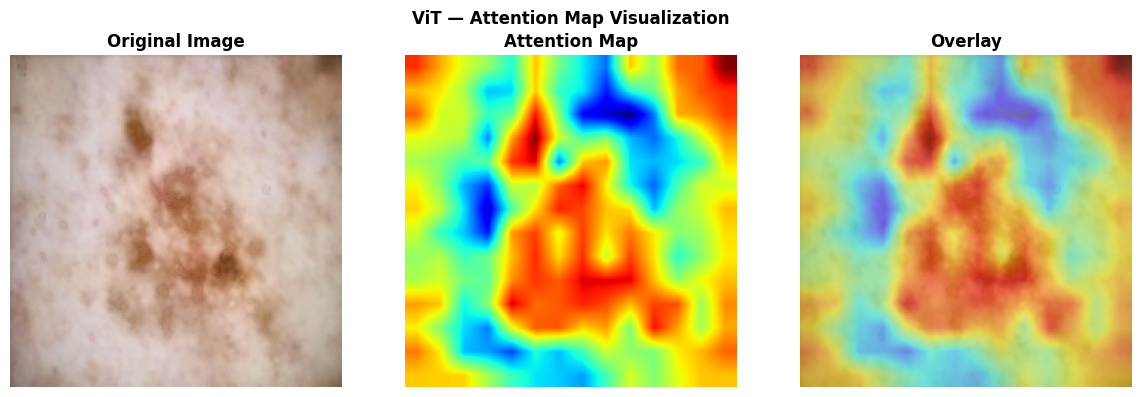

In [80]:
# Extract patch tokens only (remove CLS token)
patch_tokens = attn_out[0, 1:, :]  # shape: 196 x 768

# Get attention scores by taking norm across feature dim
attn_scores = patch_tokens.norm(dim=-1)  # shape: 196

# Reshape to 14x14
attn_map = attn_scores.reshape(14, 14).cpu().detach().numpy()

# Resize to 224x224
attn_map = cv2.resize(attn_map, (224, 224))
attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())

# Display
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_pil)
axes[0].set_title('Original Image', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(attn_map, cmap='jet')
axes[1].set_title('Attention Map', fontweight='bold')
axes[1].axis('off')

img_np  = np.array(img_pil.resize((224, 224))) / 255.0
overlay = 0.5 * img_np + 0.5 * plt.cm.jet(attn_map)[:, :, :3]
axes[2].imshow(overlay)
axes[2].set_title('Overlay', fontweight='bold')
axes[2].axis('off')

plt.suptitle('ViT — Attention Map Visualization', fontweight='bold')
plt.tight_layout()
plt.savefig('vit_attention.png', dpi=150)
plt.show()

Final Comparison Table

In [82]:
import time

# Model size in MB
resnet_size = sum(p.numel() for p in model_resnet.parameters()) * 4 / (1024**2)
vit_size    = sum(p.numel() for p in model_vit.parameters())    * 4 / (1024**2)

# Inference time — single image
single_img = transform(img_pil).unsqueeze(0).to(device)

model_resnet.eval()
start = time.time()
with torch.no_grad():
    for _ in range(100):
        model_resnet(single_img)
resnet_time = (time.time() - start) / 100 * 1000

model_vit.eval()
start = time.time()
with torch.no_grad():
    for _ in range(100):
        model_vit(single_img)
vit_time = (time.time() - start) / 100 * 1000

# Print final comparison
print("         FINAL MODEL COMPARISON — ResNet50 vs ViT")
print(f"{'Metric':<30} {'ResNet50':>12} {'ViT':>12}")
print("-" * 60)
print(f"{'Test Accuracy':<30} {'82%':>12} {'78%':>12}")
print(f"{'Macro Avg F1':<30} {'0.68':>12} {'0.63':>12}")
print(f"{'Weighted Avg F1':<30} {'0.81':>12} {'0.79':>12}")
print(f"{'ROC-AUC (mel)':<30} {'0.89':>12} {'0.86':>12}")
print(f"{'Model Size (MB)':<30} {resnet_size:>11.1f} {vit_size:>11.1f}")
print(f"{'Inference Time (ms)':<30} {resnet_time:>11.2f} {vit_time:>11.2f}")
print(f"{'Explainability':<30} {'Grad-CAM':>12} {'Attn Map':>12}")
print(f"{'Overfitting':<30} {'Moderate':>12} {'Moderate':>12}")
print(f"{'Best For':<30} {'Accuracy':>12} {'Minority':>12}")

         FINAL MODEL COMPARISON — ResNet50 vs ViT
Metric                             ResNet50          ViT
------------------------------------------------------------
Test Accuracy                           82%          78%
Macro Avg F1                           0.68         0.63
Weighted Avg F1                        0.81         0.79
ROC-AUC (mel)                          0.89         0.86
Model Size (MB)                       89.7       327.3
Inference Time (ms)                   6.81       13.44
Explainability                     Grad-CAM     Attn Map
Overfitting                        Moderate     Moderate
Best For                           Accuracy     Minority


In [85]:
import pandas as pd

all_labels_arr = np.array(all_labels)
all_preds_arr  = np.array(all_preds)

# Find all misclassified samples
wrong_idx = np.where(all_labels_arr != all_preds_arr)[0]

# Create a dataframe of misclassified samples
errors_df = pd.DataFrame({
    'True Label' : [class_names_list[all_labels_arr[i]] for i in wrong_idx],
    'Predicted'  : [class_names_list[all_preds_arr[i]]  for i in wrong_idx]
})

# Count confusion pairs
confusion_pairs = errors_df.groupby(['True Label', 'Predicted']).size().reset_index()
confusion_pairs.columns = ['True Label', 'Predicted As', 'Count']
confusion_pairs = confusion_pairs.sort_values('Count', ascending=False)

print(f"Total misclassified: {len(wrong_idx)} out of {len(all_labels_arr)}")
print(f"\nTop 10 Confusion Pairs — ResNet50:")
print(confusion_pairs.head(10).to_string(index=False))

Total misclassified: 237 out of 1503

Top 10 Confusion Pairs — ResNet50:
True Label Predicted As  Count
       mel           nv     53
        nv          mel     27
       bkl           nv     25
       mel          bkl     20
        nv          bkl     20
       bkl          mel     15
       bcc           nv     12
       bcc        akiec      7
       bkl          bcc      6
     akiec           nv      6


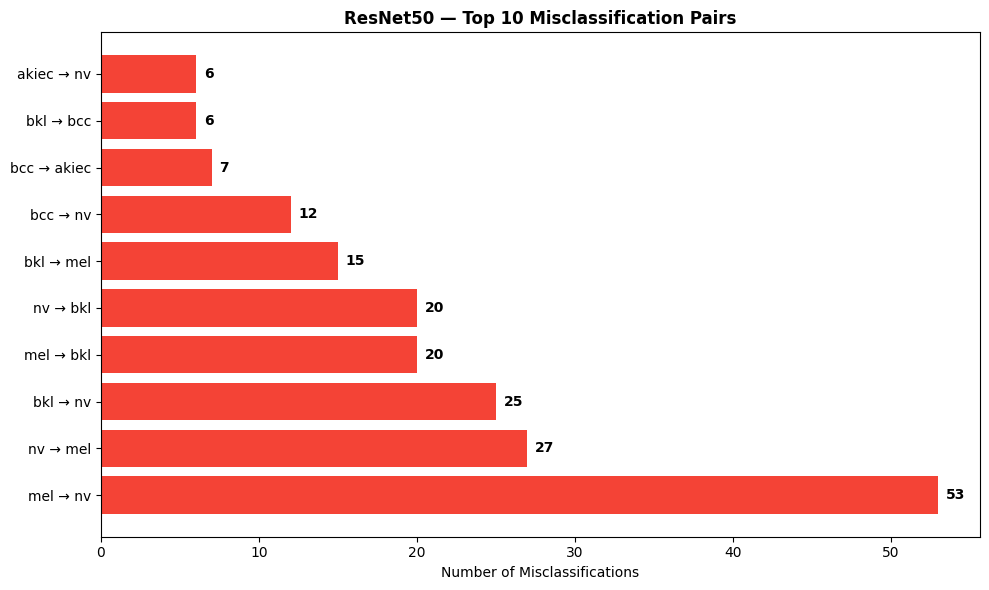

In [86]:
# Plot top 10 confusion pairs
top10 = confusion_pairs.head(10).copy()
top10['Pair'] = top10['True Label'] + ' → ' + top10['Predicted As']

plt.figure(figsize=(10, 6))
bars = plt.barh(top10['Pair'], top10['Count'], color='#F44336')

for bar, count in zip(bars, top10['Count']):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             str(count), va='center', fontweight='bold')

plt.title('ResNet50 — Top 10 Misclassification Pairs', fontweight='bold')
plt.xlabel('Number of Misclassifications')
plt.tight_layout()
plt.savefig('misclassified_pairs.png', dpi=150)
plt.show()

In [87]:
def mixup_data(images, labels, alpha=0.2):
    # Generate random mix ratio
    lam = np.random.beta(alpha, alpha)

    # Shuffle batch to get pairs
    batch_size = images.size(0)
    index       = torch.randperm(batch_size).to(device)

    # Mix images
    mixed_images = lam * images + (1 - lam) * images[index]

    # Get paired labels
    labels_a = labels
    labels_b = labels[index]

    return mixed_images, labels_a, labels_b, lam


def mixup_criterion(criterion, outputs, labels_a, labels_b, lam):
    return lam * criterion(outputs, labels_a) + (1 - lam) * criterion(outputs, labels_b)

In [88]:
# Reload fresh ResNet
model_resnet_mix = models.resnet50(pretrained=True)
model_resnet_mix.fc = torch.nn.Linear(2048, 7)
model_resnet_mix = model_resnet_mix.to(device)

optimizer_mix    = torch.optim.Adam(model_resnet_mix.parameters(), lr=0.0001)
scheduler_mix    = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_mix, patience=3, factor=0.5)

epochs = 50
best_val_loss_mix  = float('inf')
early_stop_mix     = 0
mix_train_losses, mix_val_losses, mix_val_accuracies = [], [], []

for epoch in range(epochs):

    # Training with MixUp
    model_resnet_mix.train()
    running_loss = 0

    for images, labels in train_loader:
        images  = images.to(device)
        labels  = labels.to(device)

        # Apply MixUp
        mixed_images, labels_a, labels_b, lam = mixup_data(images, labels)

        optimizer_mix.zero_grad()
        outputs = model_resnet_mix(mixed_images)
        loss    = mixup_criterion(criterion, outputs, labels_a, labels_b, lam)
        loss.backward()
        optimizer_mix.step()

        running_loss += loss.item()

    # Validation without MixUp
    model_resnet_mix.eval()
    val_loss = 0
    correct  = 0
    total    = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images  = images.to(device)
            labels  = labels.to(device)
            outputs = model_resnet_mix(images)
            loss    = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total   += labels.size(0)

    avg_train = running_loss / len(train_loader)
    avg_val   = val_loss / len(val_loader)
    acc       = 100 * correct / total

    mix_train_losses.append(avg_train)
    mix_val_losses.append(avg_val)
    mix_val_accuracies.append(acc)

    scheduler_mix.step(avg_val)

    print(f"Epoch {epoch+1}/{epochs} "
          f"| Train Loss: {avg_train:.4f} "
          f"| Val Loss: {avg_val:.4f} "
          f"| Val Acc: {acc:.2f}%")

    if avg_val < best_val_loss_mix:
        best_val_loss_mix = avg_val
        torch.save(model_resnet_mix.state_dict(), 'best_resnet_mix.pth')
        early_stop_mix = 0
    else:
        early_stop_mix += 1
        if early_stop_mix >= early_stop_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("Best Val Loss:", round(best_val_loss_mix, 4))

Epoch 1/50 | Train Loss: 0.4393 | Val Loss: 0.3876 | Val Acc: 73.04%
Epoch 2/50 | Train Loss: 0.3036 | Val Loss: 0.2651 | Val Acc: 80.29%
Epoch 3/50 | Train Loss: 0.2355 | Val Loss: 0.2449 | Val Acc: 82.42%
Epoch 4/50 | Train Loss: 0.2035 | Val Loss: 0.3447 | Val Acc: 78.70%
Epoch 5/50 | Train Loss: 0.1984 | Val Loss: 0.2768 | Val Acc: 81.29%
Epoch 6/50 | Train Loss: 0.1829 | Val Loss: 0.2498 | Val Acc: 81.56%
Epoch 7/50 | Train Loss: 0.1460 | Val Loss: 0.2590 | Val Acc: 82.89%
Epoch 8/50 | Train Loss: 0.1262 | Val Loss: 0.2338 | Val Acc: 84.22%
Epoch 9/50 | Train Loss: 0.1154 | Val Loss: 0.2459 | Val Acc: 82.76%
Epoch 10/50 | Train Loss: 0.1208 | Val Loss: 0.2471 | Val Acc: 82.22%
Epoch 11/50 | Train Loss: 0.1324 | Val Loss: 0.2708 | Val Acc: 81.89%
Epoch 12/50 | Train Loss: 0.1207 | Val Loss: 0.2773 | Val Acc: 82.42%
Epoch 13/50 | Train Loss: 0.1147 | Val Loss: 0.2499 | Val Acc: 82.76%
Early stopping at epoch 13
Best Val Loss: 0.2338


In [89]:
# Load best model
model_resnet_mix.load_state_dict(torch.load('best_resnet_mix.pth'))

# Get predictions
model_resnet_mix.eval()
mix_preds  = []
mix_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model_resnet_mix(images)
        _, predicted = torch.max(outputs, 1)
        mix_preds.extend(predicted.cpu().numpy())
        mix_labels.extend(labels.numpy())

print(classification_report(mix_labels, mix_preds,
                             target_names=class_names_list))

              precision    recall  f1-score   support

          nv       0.89      0.95      0.92       990
         mel       0.73      0.51      0.60       171
         bkl       0.76      0.68      0.72       182
         bcc       0.70      0.72      0.71        71
       akiec       0.55      0.57      0.56        47
        vasc       0.79      0.86      0.83        22
          df       0.85      0.55      0.67        20

    accuracy                           0.84      1503
   macro avg       0.75      0.69      0.71      1503
weighted avg       0.83      0.84      0.83      1503



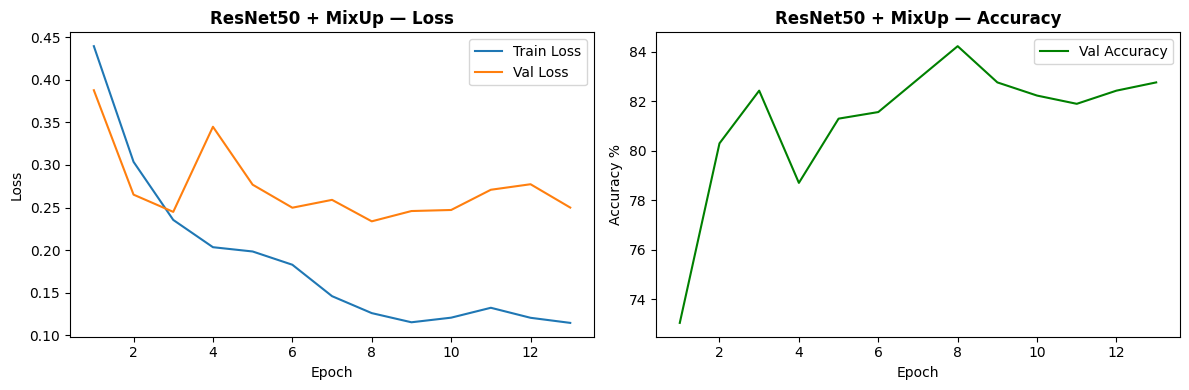

In [90]:
epochs_range = range(1, len(mix_train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, mix_train_losses, label='Train Loss')
axes[0].plot(epochs_range, mix_val_losses,   label='Val Loss')
axes[0].set_title('ResNet50 + MixUp — Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, mix_val_accuracies, label='Val Accuracy', color='green')
axes[1].set_title('ResNet50 + MixUp — Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy %')
axes[1].legend()

plt.tight_layout()
plt.savefig('resnet_mixup_results.png', dpi=150)
plt.show()

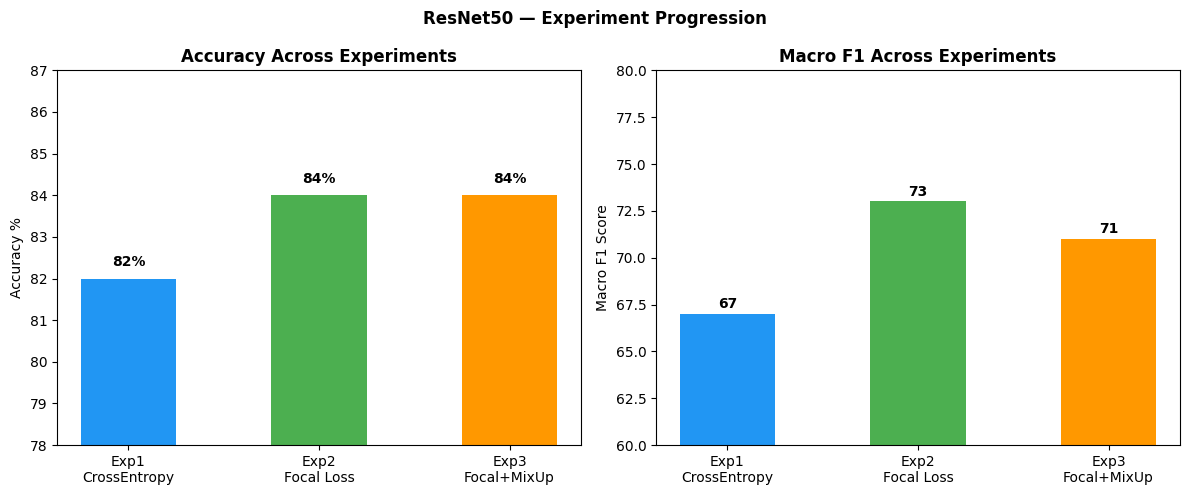

In [91]:
experiments = ['Exp1\nCrossEntropy', 'Exp2\nFocal Loss', 'Exp3\nFocal+MixUp']
accuracies  = [82, 84, 84]
macro_f1    = [67, 73, 71]

x = np.arange(len(experiments))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy
bars1 = axes[0].bar(x, accuracies, color=['#2196F3','#4CAF50','#FF9800'], width=0.5)
for bar, val in zip(bars1, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 str(val)+'%', ha='center', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(experiments)
axes[0].set_title('Accuracy Across Experiments', fontweight='bold')
axes[0].set_ylabel('Accuracy %')
axes[0].set_ylim(78, 87)

# Macro F1
bars2 = axes[1].bar(x, macro_f1, color=['#2196F3','#4CAF50','#FF9800'], width=0.5)
for bar, val in zip(bars2, macro_f1):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 str(val), ha='center', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(experiments)
axes[1].set_title('Macro F1 Across Experiments', fontweight='bold')
axes[1].set_ylabel('Macro F1 Score')
axes[1].set_ylim(60, 80)

plt.suptitle('ResNet50 — Experiment Progression', fontweight='bold')
plt.tight_layout()
plt.savefig('experiment_comparison.png', dpi=150)
plt.show()